# Sweet Spot: recorded contacts and session maps

This simplified notebook covers **recorded hits/misses, repeated contacts, and maps for the 15 retained sessions**.
Raw measurements are preserved. IMU, timing, calibration offsets, and software-history analysis are outside the current scope.
The previous detailed analysis is stored in `archive/detailed_analysis/` as a historical snapshot.

Sessions **3, 4, 6, 7, and 9** were excluded retrospectively by the operator as interrupted trials.
Sessions **12 and 13** are retained as complete six-target trials (two trios), based on operator confirmation.
Their JSON configuration reports nine targets; both quantities remain documented, and original target IDs are preserved.
The logged IDs do not independently verify two complete RGB trios, particularly in session 13. This metadata discrepancy is unresolved.

An event is a JSONL row. A recorded contact has non-null touch coordinates. A `no_touch` row is not a detected contact.
Hit/miss labels and assigned target IDs come from the application; they do not prove the robot's intended target.
Run all cells from the repository root or the `notebooks/` directory.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
import csv
import hashlib
import html
import json
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / 'data/raw/sweetspot').exists():
    ROOT = ROOT.parent
BASE = ROOT
SOURCE = ROOT / "data/raw/sweetspot/touch_results_2026-10-06-sweetspot.jsonl"
if not SOURCE.exists():
    raise FileNotFoundError("Run the notebook from the phone-test-results repository root.")
OUTPUT = ROOT / "results/sweetspot"
TABLES = OUTPUT / "tables"
ANNOTATIONS = ROOT / "data/annotations"
for folder in [OUTPUT, TABLES, OUTPUT / "maps", OUTPUT / "figures"]:
    folder.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(exist_ok=True)
LOCAL_TIMEZONE = ZoneInfo("America/Recife")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})

def show_table(rows, fields=None):
    if not rows:
        display(Markdown("No records."))
        return
    fields = fields or list(rows[0])
    def esc(v):
        return html.escape(str(v))
    display(HTML("<div style='overflow-x:auto'><table><thead><tr>" +
                 "".join(f"<th>{esc(c)}</th>" for c in fields) + "</tr></thead><tbody>" +
                 "".join("<tr>" + "".join(f"<td>{esc(l.get(c, ''))}</td>" for c in fields) + "</tr>" for l in rows) +
                 "</tbody></table></div>"))

def write_csv(path, rows, fields=None):
    fields = fields or (list(rows[0]) if rows else [])
    with Path(path).open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

def save_figure(name, fig):
    (OUTPUT / name).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT / name, dpi=300, bbox_inches="tight")
    if name.startswith("figures/"):
        fig.savefig(OUTPUT / Path(name).with_suffix(".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

raw = SOURCE.read_bytes()
records = []
for line_number, text in enumerate(raw.decode("utf-8").splitlines(), 1):
    if text.strip():
        r = json.loads(text)
        r["source_line"] = line_number
        r["timestamp"] = datetime.fromisoformat(r["date_time"].replace("Z", "+00:00"))
        records.append(r)
assert records, "The source contains no events."
records.sort(key=lambda r: (r["timestamp"], r["source_line"]))
groups = defaultdict(list)
for r in records:
    groups[r["session_id"]].append(r)
session_order = sorted(groups, key=lambda s: groups[s][0]["timestamp"])
session_number = {s: i for i, s in enumerate(session_order, 1)}
touches = [r for r in records if r["actual_touch_x"] is not None and r["actual_touch_y"] is not None]
print(f"{len(records)} events; {len(groups)} sessions; {len(touches)} contacts with coordinates.")
print("SHA-256:", hashlib.sha256(raw).hexdigest())
print("Recorded event interval:", records[0]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat(), "to", records[-1]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat())
print("App outcomes:", dict(Counter(r["result"] for r in records)))

assert len({r["event_id"] for r in records}) == len(records), "Duplicate event_id"
assert len({r["test_id"] for r in records}) == len(groups), "test_id reused across sessions"
for sid, rs in groups.items():
    assert len({r["test_id"] for r in rs}) == 1
    assert len({json.dumps(r["configuration"], sort_keys=True) for r in rs}) == 1
    config = rs[0]["configuration"]
    assert config["target_count"] == 3 * config["rgb_trios_per_spawn"]
    expected_ids = {f"trio-{i:03d}-{color}" for i in range(1, config["rgb_trios_per_spawn"] + 1) for color in ("red", "green", "blue")}
    assert {r["target_id"] for r in rs} <= expected_ids
    geometry = defaultdict(set)
    for r in rs:
        geometry[r["target_id"]].add((r["target_center_x"], r["target_center_y"], r["target_radius"]))
    assert all(len(v) == 1 for v in geometry.values()), "Target geometry changed within a session"
for r in records:
    assert (r["actual_touch_x"] is None) == (r["actual_touch_y"] is None)
    assert r["response_time_ms"] >= 0 and r["target_radius"] > 0
    assert 0 <= r["target_center_x"] <= r["screen_width"]
    assert 0 <= r["target_center_y"] <= r["screen_height"]
    assert math.isclose(r["target_diameter"], 2 * r["target_radius"])
    if r["actual_touch_x"] is None:
        assert r["result"] == "no_touch" and r["distance_to_center"] is None and not r["inside_target"]
    else:
        d = math.hypot(r["actual_touch_x"] - r["target_center_x"], r["actual_touch_y"] - r["target_center_y"])
        assert math.isclose(d, r["distance_to_center"], abs_tol=.001)
        assert r["inside_target"] == (d <= r["target_radius"])
        assert r["result"] == ("hit" if r["inside_target"] else "miss")
print("Data integrity checks passed.")
print("Screen dimensions:", sorted({(r['screen_width'], r['screen_height']) for r in records}))
print("Timeout flags:", sum(r["timed_out"] for r in records))
print("previous_attempts matches the event index in every session:",
      all([r["previous_attempts_in_session"] for r in groups[s]] == list(range(len(groups[s]))) for s in session_order))

177 events; 20 sessions; 137 contacts with coordinates.
SHA-256: 290accd48b1739358913f6846d241b868f7a73a8317a14dd1b178490747f67f5
Recorded event interval: 2026-10-06T14:40:15.572563-03:00 to 2026-10-06T15:37:46.275336-03:00
App outcomes: {'hit': 111, 'miss': 26, 'no_touch': 40}
Data integrity checks passed.
Screen dimensions: [(1080, 2400)]
Timeout flags: 0
previous_attempts matches the event index in every session: True


In [2]:
EXCLUDED_SESSION_NUMBERS = {3, 4, 6, 7, 9}
OPERATOR_TARGET_COUNTS = {12: 6, 13: 6}
original_records = records.copy()
original_groups = dict(groups)
original_order = session_order.copy()
assert EXCLUDED_SESSION_NUMBERS <= set(session_number.values())
EXCLUDED_OUTPUT = ROOT / 'data/excluded'
EXCLUDED_OUTPUT.mkdir(exist_ok=True)
excluded_sessions = []
for sid in original_order:
    if session_number[sid] not in EXCLUDED_SESSION_NUMBERS:
        continue
    rs = original_groups[sid]
    excluded_sessions.append(dict(session_number=session_number[sid], session_id=sid, test_id=rs[0]['test_id'],
        reason='Interrupted trial; excluded retrospectively by the operator',
        logged_target_count=rs[0]['configuration']['target_count'], events=len(rs),
        touches=sum(r['actual_touch_x'] is not None for r in rs),
        hits=sum(r['result'] == 'hit' for r in rs), misses=sum(r['result'] == 'miss' for r in rs),
        no_touch=sum(r['result'] == 'no_touch' for r in rs)))
excluded_line_numbers = {r['source_line'] for r in original_records if session_number[r['session_id']] in EXCLUDED_SESSION_NUMBERS}
source_lines = raw.splitlines(keepends=True)
(EXCLUDED_OUTPUT / 'sweetspot_excluded.jsonl').write_bytes(b''.join(line for i, line in enumerate(source_lines, 1) if i in excluded_line_numbers))
(ROOT / 'data/processed/sweetspot_valid.jsonl').write_bytes(b''.join(line for i, line in enumerate(source_lines, 1) if line.strip() and i not in excluded_line_numbers))
write_csv(ANNOTATIONS / 'exclusions.csv', excluded_sessions)
session_order = [sid for sid in original_order if session_number[sid] not in EXCLUDED_SESSION_NUMBERS]
groups = {sid: original_groups[sid] for sid in session_order}
records = [r for r in original_records if r['session_id'] in groups]
touches = [r for r in records if r['actual_touch_x'] is not None]
assert len(records) + len(excluded_line_numbers) == len(original_records)
assert len(groups) + len(excluded_sessions) == len(original_groups)

def expected_target_ids(sid):
    rs = original_groups[sid]
    if session_number[sid] in OPERATOR_TARGET_COUNTS:
        ids = sorted({r['target_id'] for r in rs})
        assert len(ids) == OPERATOR_TARGET_COUNTS[session_number[sid]]
        return ids
    config = rs[0]['configuration']
    return sorted(f"trio-{i:03d}-{color}" for i in range(1, config['rgb_trios_per_spawn'] + 1)
                  for color in ('red', 'green', 'blue'))

operator_annotations = []
for sid in session_order:
    if session_number[sid] not in OPERATOR_TARGET_COUNTS:
        continue
    ids = expected_target_ids(sid)
    color_counts = Counter(tid.rsplit('-', 1)[-1] for tid in ids)
    operator_annotations.append(dict(session_number=session_number[sid], session_id=sid,
        logged_target_count=original_groups[sid][0]['configuration']['target_count'],
        effective_target_count=OPERATOR_TARGET_COUNTS[session_number[sid]], operator_reported_trio_count=2,
        completion_basis='Operator confirms completed trial with six displayed targets',
        annotation_source='Operator clarification in the analysis conversation',
        logged_red_ids=color_counts['red'], logged_green_ids=color_counts['green'], logged_blue_ids=color_counts['blue'],
        target_ids=';'.join(ids), metadata_discrepancy='Raw target count and/or identifiers do not verify the reported two-trio layout'))
write_csv(ANNOTATIONS / 'operator_target_counts.csv', operator_annotations)
show_table(excluded_sessions)
show_table(operator_annotations)
print(f'Retained: {len(groups)} sessions, {len(records)} events, {len(touches)} recorded contacts.')
print(f'Excluded: {len(excluded_sessions)} sessions, {len(excluded_line_numbers)} events. Original session numbering retained.')

session_number,session_id,test_id,reason,logged_target_count,events,touches,hits,misses,no_touch
3,2b53e46e-4e49-4820-93a9-6c4edf8cac94,6dfaba85-7784-4d1c-9153-588822e7ee3d,Interrupted trial; excluded retrospectively by the operator,12,1,1,0,1,0
4,bf8e71e5-5c28-400b-a3f7-145561d2774f,ba2db20e-eb9c-4350-ad3e-0ab771083ba6,Interrupted trial; excluded retrospectively by the operator,12,1,1,0,1,0
6,d0437ec4-5e99-4090-af84-f0aad33b75b5,fef809f4-8c67-4203-b292-b26e2dc8dd8f,Interrupted trial; excluded retrospectively by the operator,12,1,1,0,1,0
7,71dbf087-c4b8-4aab-8ca0-895bd33fd4c6,b87f7df5-2bb7-447f-9076-080bc4bd1d4f,Interrupted trial; excluded retrospectively by the operator,9,1,1,0,1,0
9,7fc20fd5-ead3-41a7-99fb-3cd055b9e6c2,bd7d6332-f5b5-411b-b9fd-176c4427d6ad,Interrupted trial; excluded retrospectively by the operator,9,10,1,0,1,9


session_number,session_id,logged_target_count,effective_target_count,operator_reported_trio_count,completion_basis,annotation_source,logged_red_ids,logged_green_ids,logged_blue_ids,target_ids,metadata_discrepancy
12,277529fc-a0e6-44b5-b811-f69de2f4bf86,9,6,2,Operator confirms completed trial with six displayed targets,Operator clarification in the analysis conversation,2,2,2,trio-001-blue;trio-001-green;trio-001-red;trio-003-blue;trio-003-green;trio-003-red,Raw target count and/or identifiers do not verify the reported two-trio layout
13,65031c8f-8bbe-4e4a-8673-6a2551c16c0d,9,6,2,Operator confirms completed trial with six displayed targets,Operator clarification in the analysis conversation,2,3,1,trio-001-green;trio-002-green;trio-002-red;trio-003-blue;trio-003-green;trio-003-red,Raw target count and/or identifiers do not verify the reported two-trio layout


Retained: 15 sessions, 163 events, 132 recorded contacts.
Excluded: 5 sessions, 14 events. Original session numbering retained.


## 1. Observed outcomes

The contact-level hit fraction counts all registered contacts, including rapid repeats.
The target-level fraction counts each target once if it has at least one hit.
The primary target denominator uses the operator-confirmed six targets in sessions 12 and 13; the raw-count denominator is shown separately.
These are descriptive recorded outcomes, not independent robot-action accuracy or estimates of contacts that were never logged.

session_number,radius_dp,effective_target_count,logged_target_count,touches,hits,misses,no_touch
1,50,6,6,6,5,1,1
2,50,12,12,12,12,0,1
5,45,12,12,12,10,2,3
8,40,9,9,9,9,0,1
10,40,9,9,9,9,0,1
11,35,9,9,9,8,1,2
12,35,6,9,6,5,1,0
13,35,6,9,6,6,0,0
14,35,9,9,9,7,2,3
15,35,9,9,9,8,1,2


measure,numerator,denominator,fraction
Recorded-contact hit fraction,111,132,0.8409090909090909
Target hit coverage: operator-corrected counts,111,135,0.8222222222222222
Target hit coverage: raw configuration counts,111,141,0.7872340425531915


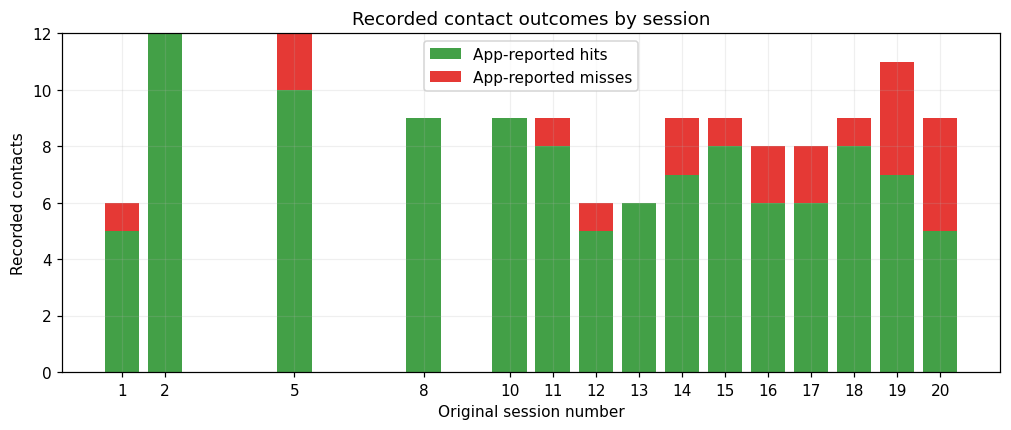

In [3]:
sessions, targets = [], []
for sid in session_order:
    rs = groups[sid]
    config = rs[0]["configuration"]
    by_target = defaultdict(list)
    for r in rs:
        by_target[r["target_id"]].append(r)
    expected_ids = expected_target_ids(sid)
    n = len(expected_ids)
    target_summaries = []
    for tid in expected_ids:
        ev = by_target.get(tid, [])
        results = [r["result"] for r in ev]
        hit = "hit" in results
        miss = "miss" in results
        no_touch_seen = "no_touch" in results
        status = "hit" if hit else "miss_without_hit" if miss else "no_touch_only" if no_touch_seen else "unrecorded"
        a = dict(session_number=session_number[sid], session_id=sid, target_id=tid, status=status,
                 events=len(ev), touches=sum(r["actual_touch_x"] is not None for r in ev),
                 miss_followed_by_hit=hit and any(r["result"] == "miss" for r in ev[:next((j for j, r in enumerate(ev) if r["result"] == "hit"), len(ev))]),
                 hit_and_no_touch=hit and no_touch_seen, result_sequence=" → ".join(results))
        targets.append(a)
        target_summaries.append(a)
    counts = Counter(r["result"] for r in rs)
    statuses = Counter(a["status"] for a in target_summaries)
    nt = counts["hit"] + counts["miss"]
    s = dict(session_number=session_number[sid], session_id=sid, test_id=rs[0]["test_id"],
             first_event_local=rs[0]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat(),
             last_event_local=rs[-1]["timestamp"].astimezone(LOCAL_TIMEZONE).isoformat(),
             event_span_s=round((rs[-1]["timestamp"] - rs[0]["timestamp"]).total_seconds(), 3),
             radius_dp=rs[0]["target_radius_dp"], effective_target_count=n, logged_target_count=config["target_count"],
             configuration_discrepancy=n != config["target_count"], target_count_source="operator" if session_number[sid] in OPERATOR_TARGET_COUNTS else "JSON", completion_basis='operator_confirmed' if session_number[sid] in OPERATOR_TARGET_COUNTS else 'all_expected_ids_recorded' if len(by_target) == n else 'not_established', events=len(rs), touches=nt,
             recorded_target_count=len(by_target), hits=counts["hit"], misses=counts["miss"], no_touch=counts["no_touch"],
             targets_with_hit=statuses["hit"], targets_with_miss_without_hit=statuses["miss_without_hit"],
             targets_with_no_touch_only=statuses["no_touch_only"], targets_without_records=statuses["unrecorded"],
             targets_with_miss_followed_by_hit=sum(a["miss_followed_by_hit"] for a in target_summaries),
             hit_and_no_touch=sum(a["hit_and_no_touch"] for a in target_summaries),
             missing_target_records=statuses["unrecorded"] > 0)
    sessions.append(s)

show_table(sessions, ['session_number', 'radius_dp', 'effective_target_count', 'logged_target_count', 'touches', 'hits', 'misses', 'no_touch'])
write_csv(TABLES / 'sessions.csv', sessions)

total_contacts = sum(s['touches'] for s in sessions)
total_hits = sum(s['hits'] for s in sessions)
hit_targets = sum(s['targets_with_hit'] for s in sessions)
effective_targets = sum(s['effective_target_count'] for s in sessions)
logged_targets = sum(s['logged_target_count'] for s in sessions)
metrics = [
    dict(measure='Recorded-contact hit fraction', numerator=total_hits, denominator=total_contacts, fraction=total_hits / total_contacts),
    dict(measure='Target hit coverage: operator-corrected counts', numerator=hit_targets, denominator=effective_targets, fraction=hit_targets / effective_targets),
    dict(measure='Target hit coverage: raw configuration counts', numerator=hit_targets, denominator=logged_targets, fraction=hit_targets / logged_targets),
]
show_table(metrics)
write_csv(TABLES / 'metrics.csv', metrics)
fig, ax = plt.subplots(figsize=(11, 4))
x = [s['session_number'] for s in sessions]
ax.bar(x, [s['hits'] for s in sessions], label='App-reported hits', color='#43a047')
ax.bar(x, [s['misses'] for s in sessions], bottom=[s['hits'] for s in sessions], label='App-reported misses', color='#e53935')
ax.set(xticks=x, xlabel='Original session number', ylabel='Recorded contacts', title='Recorded contact outcomes by session')
ax.legend()
save_figure('figures/contact_outcomes.png', fig)

## 2. Repeated contacts

Compare actual coordinates and UTC event timestamps, independently of the app's target assignments.
The exploratory nearby-contact threshold is **8 dp (20 px here)**; a rapid-repeat candidate also has an interval ≤ **300 ms**.
The same-target-region criterion permits a margin of **20 dp** outside the nearest circle.
These adjustable criteria identify repeated recorded locations; they do not establish the physical cause of a double click.
All contacts remain in the outcome fractions above.

In [4]:
NEARBY_DISTANCE_DP = 8
RAPID_CONTACT_WINDOW_MS = 300
TARGET_MARGIN_DP = 20
assert NEARBY_DISTANCE_DP > 0 and RAPID_CONTACT_WINDOW_MS > 0 and TARGET_MARGIN_DP >= 0

from itertools import combinations

def detect_pairs(rs):
    ts = [r for r in rs if r['actual_touch_x'] is not None]
    geometries = {r['target_id']: r for r in rs}
    density = rs[0]['target_radius'] / rs[0]['target_radius_dp']
    def target_distance(r, q):
        return math.hypot(r['actual_touch_x'] - q['target_center_x'], r['actual_touch_y'] - q['target_center_y'])
    nearest_targets = [min(geometries.values(), key=lambda q: target_distance(r, q)) for r in ts]
    pairs = []
    # ponytail: O(n²) for short sessions; use a spatial index if sessions become large.
    for (i, a), (j, b) in combinations(enumerate(ts, 1), 2):
        qa, qb = nearest_targets[i - 1], nearest_targets[j - 1]
        distance = math.hypot(a['actual_touch_x'] - b['actual_touch_x'], a['actual_touch_y'] - b['actual_touch_y'])
        dt = (b['timestamp'] - a['timestamp']).total_seconds() * 1000
        nearby = distance <= NEARBY_DISTANCE_DP * density
        same_target_region = (qa['target_id'] == qb['target_id'] and
                        target_distance(a, qa) <= qa['target_radius'] + TARGET_MARGIN_DP * density and
                        target_distance(b, qb) <= qb['target_radius'] + TARGET_MARGIN_DP * density)
        pairs.append(dict(touch_a=i, touch_b=j, distance_px=distance, interval_ms=dt,
            nearby=nearby, event_id_a=a['event_id'], event_id_b=b['event_id'],
            rapid_repeated_contact_candidate=nearby and 0 <= dt <= RAPID_CONTACT_WINDOW_MS,
            same_target_region=same_target_region, shared_nearest_target_id=qa['target_id'] if same_target_region else '',
            assigned_target_a=a['target_id'], assigned_target_b=b['target_id'],
            result_a=a['result'], result_b=b['result'],
            x_a=a['actual_touch_x'], y_a=a['actual_touch_y'], x_b=b['actual_touch_x'], y_b=b['actual_touch_y'],
            nearest_target_distance_a_px=target_distance(a, qa), nearest_target_distance_b_px=target_distance(b, qb),
            source_line_a=a['source_line'], source_line_b=b['source_line'],
            event_time_a_utc=a['date_time'], event_time_b_utc=b['date_time']))
    return pairs

touch_pairs = []
for sid in session_order:
    for pair in detect_pairs(groups[sid]):
        touch_pairs.append(dict(session_number=session_number[sid], session_id=sid, **pair))
nearby_pairs = [p for p in touch_pairs if p['nearby']]
rapid_pairs = [p for p in touch_pairs if p['rapid_repeated_contact_candidate']]
same_region_pairs = [p for p in touch_pairs if p['same_target_region']]
write_csv(TABLES / 'repeated_contacts.csv', [p for p in touch_pairs if p['nearby'] or p['same_target_region']])

show_table([dict(session_number=p['session_number'], touches=f"{p['touch_a']} and {p['touch_b']}",
             distance_px=round(p['distance_px'], 2), interval_ms=round(p['interval_ms'], 1),
             shared_nearest_target_id=p['shared_nearest_target_id'],
             result=f"{p['result_a']} → {p['result_b']}",
             app_assignment=f"{p['assigned_target_a']} → {p['assigned_target_b']}",
             rapid_repeated_contact_candidate=p['rapid_repeated_contact_candidate'])
        for p in touch_pairs if p['nearby'] or p['same_target_region']])

display(Markdown(f"""
**{len(nearby_pairs)} nearby pairs** in **{len({p['session_number'] for p in nearby_pairs})} retained sessions**:
{', '.join(str(n) for n in sorted({p['session_number'] for p in nearby_pairs}))}.
{len(rapid_pairs)} pairs meet the exploratory rapid-repeat criterion; {len(same_region_pairs)} pairs occupy the same nearest-target region.
{sum(p['assigned_target_a'] != p['assigned_target_b'] for p in nearby_pairs)} nearby pairs have different app target assignments.
Spatial comparison therefore reveals repeated locations that a target-ID-only analysis would miss.
"""))
show_table([dict(distance_threshold_px=d, pairs=sum(p['distance_px'] <= d for p in touch_pairs),
             sessions=', '.join(str(n) for n in sorted({p['session_number'] for p in touch_pairs if p['distance_px'] <= d})))
        for d in [5, 20, 50, 100]])

session_number,touches,distance_px,interval_ms,shared_nearest_target_id,result,app_assignment,rapid_repeated_contact_candidate
5,5 and 6,2.35,73.3,trio-001-green,hit → miss,trio-001-green → trio-003-green,True
14,3 and 4,2.74,60.5,trio-001-red,hit → miss,trio-001-red → trio-002-blue,True
15,2 and 3,3.83,72.1,trio-003-green,hit → miss,trio-003-green → trio-002-blue,True
19,1 and 2,3.02,67.7,trio-003-red,miss → miss,trio-003-red → trio-003-red,True



**4 nearby pairs** in **4 retained sessions**:
5, 14, 15, 19.
4 pairs meet the exploratory rapid-repeat criterion; 4 pairs occupy the same nearest-target region.
3 nearby pairs have different app target assignments.
Spatial comparison therefore reveals repeated locations that a target-ID-only analysis would miss.


distance_threshold_px,pairs,sessions
5,4,"5, 14, 15, 19"
20,4,"5, 14, 15, 19"
50,4,"5, 14, 15, 19"
100,4,"5, 14, 15, 19"


## 3. Session maps

Coordinates use the logged **1080 × 2400 px** test surface, with the origin at the top left and y increasing downward.
Circles show original target centers/radii. Black points and crosses preserve app-reported hits/misses.
Numbers show contact order; magenta rings and zoom panels show nearby contacts. Manual `no_touch` events have no contact point.
The maps are not robot trajectories or complete screen captures.

The primary PDF and overview contain the 15 retained sessions. English maps of the five excluded sessions are preserved separately.
Sessions 12 and 13 show **6/6** with a note documenting the raw nine-target configuration.

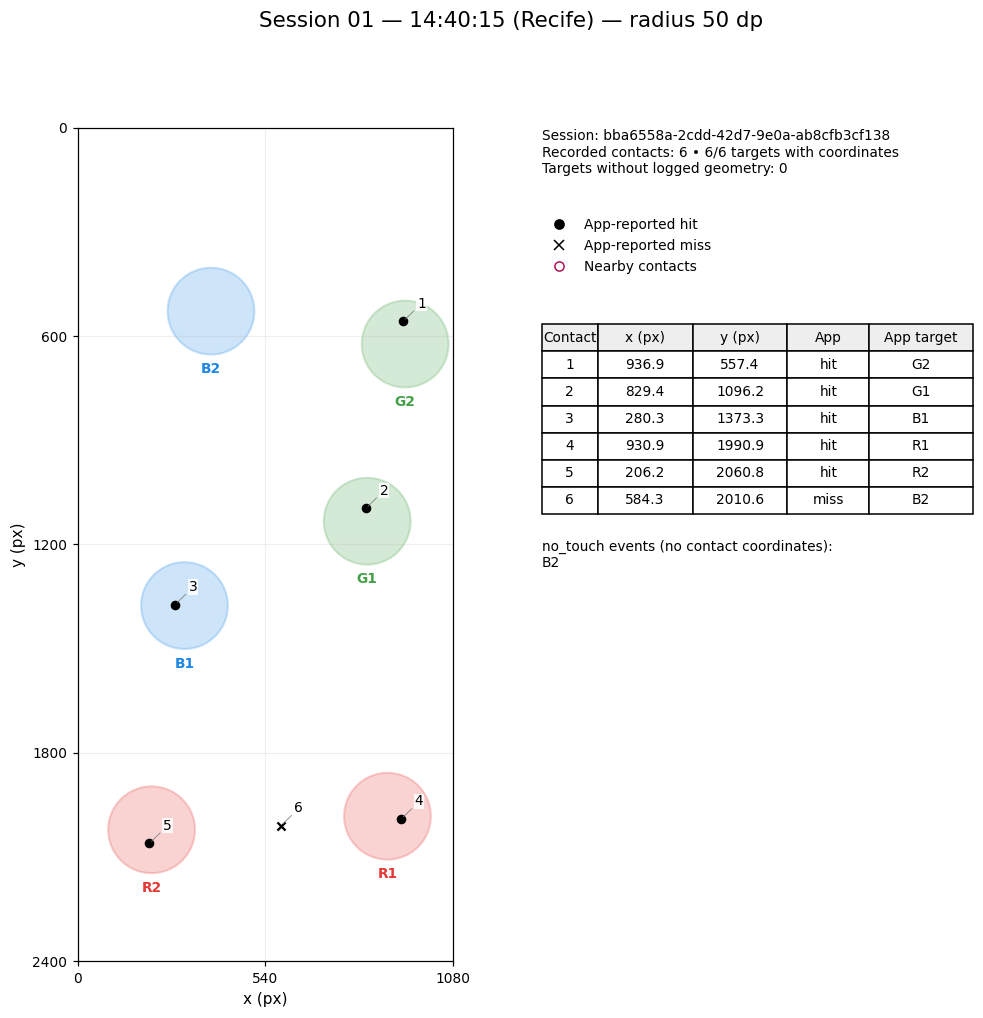

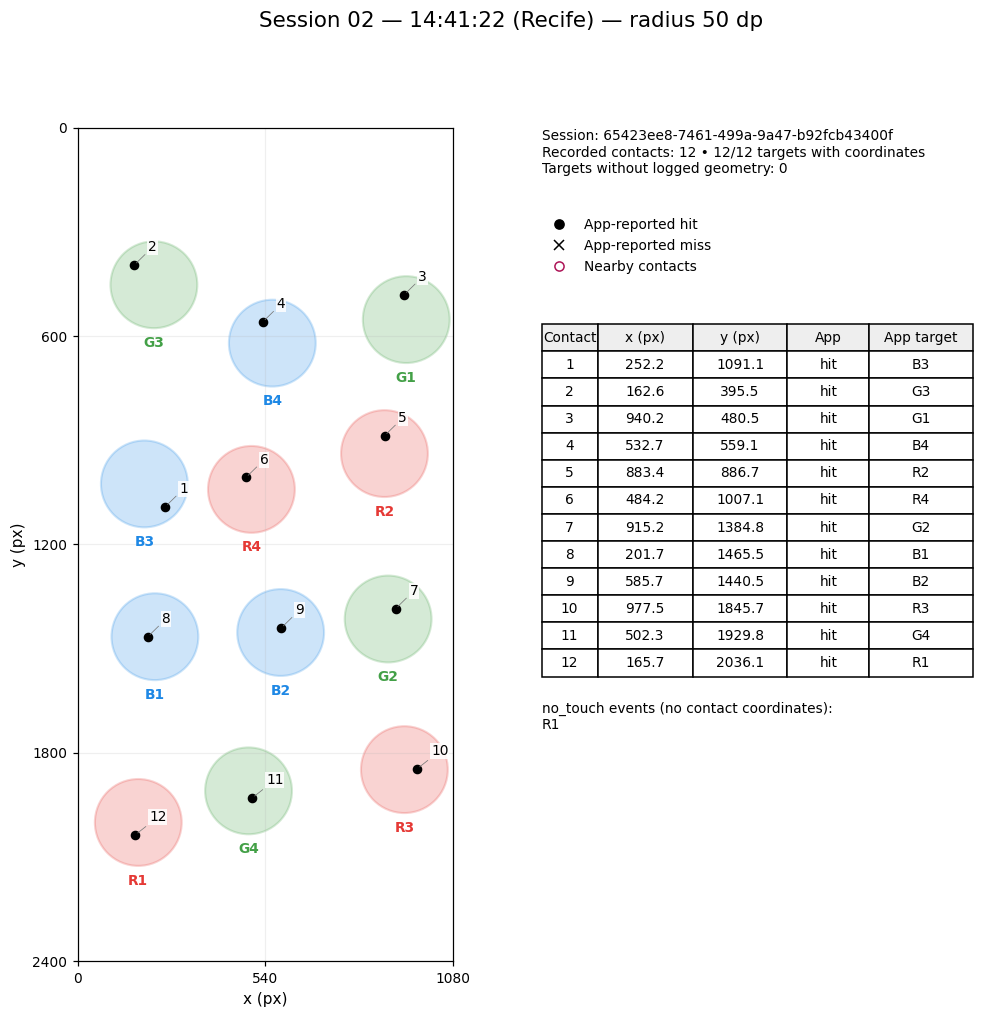

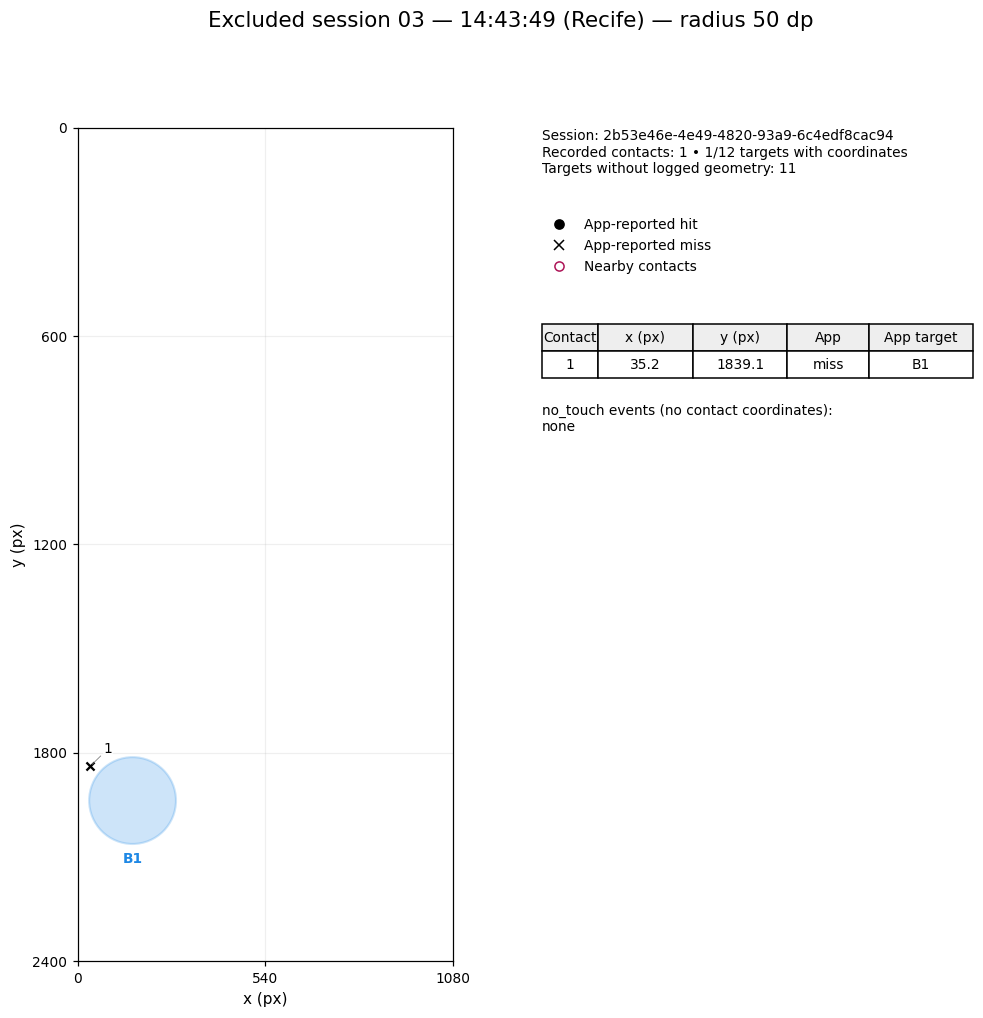

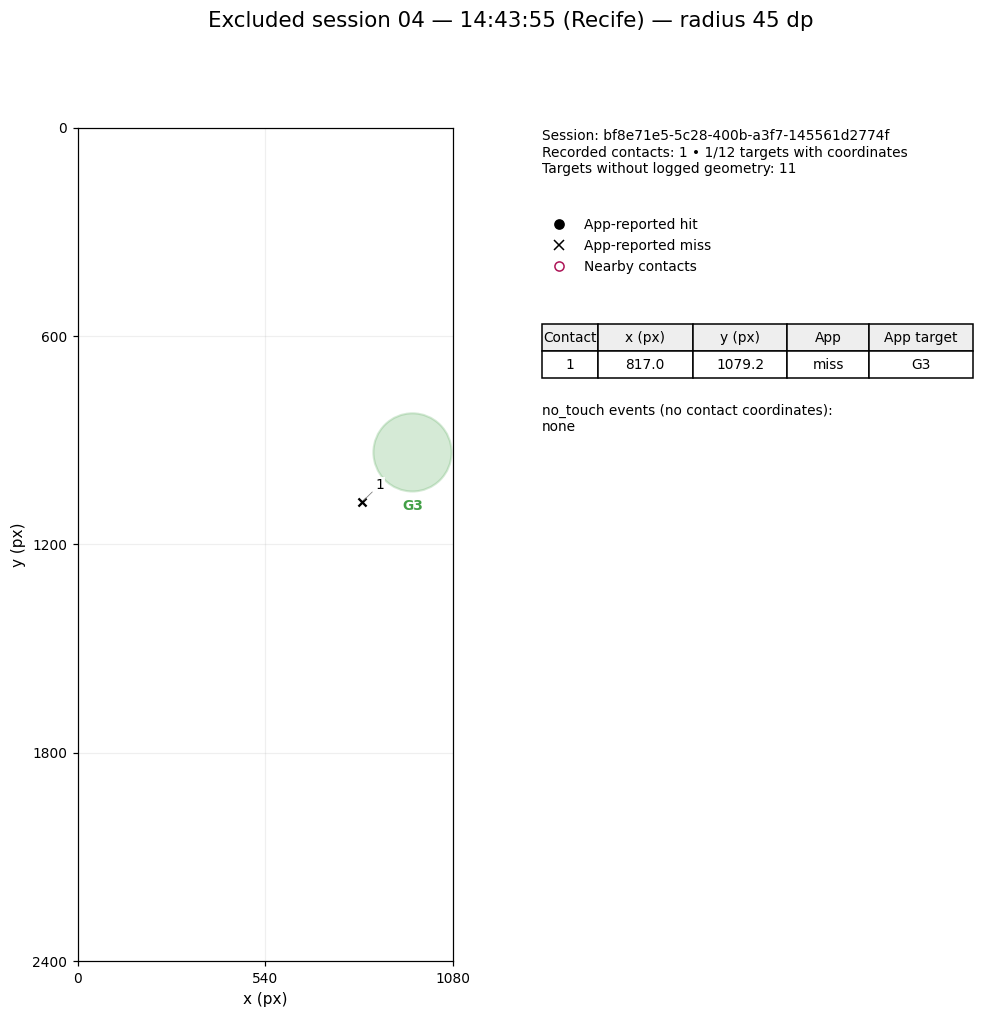

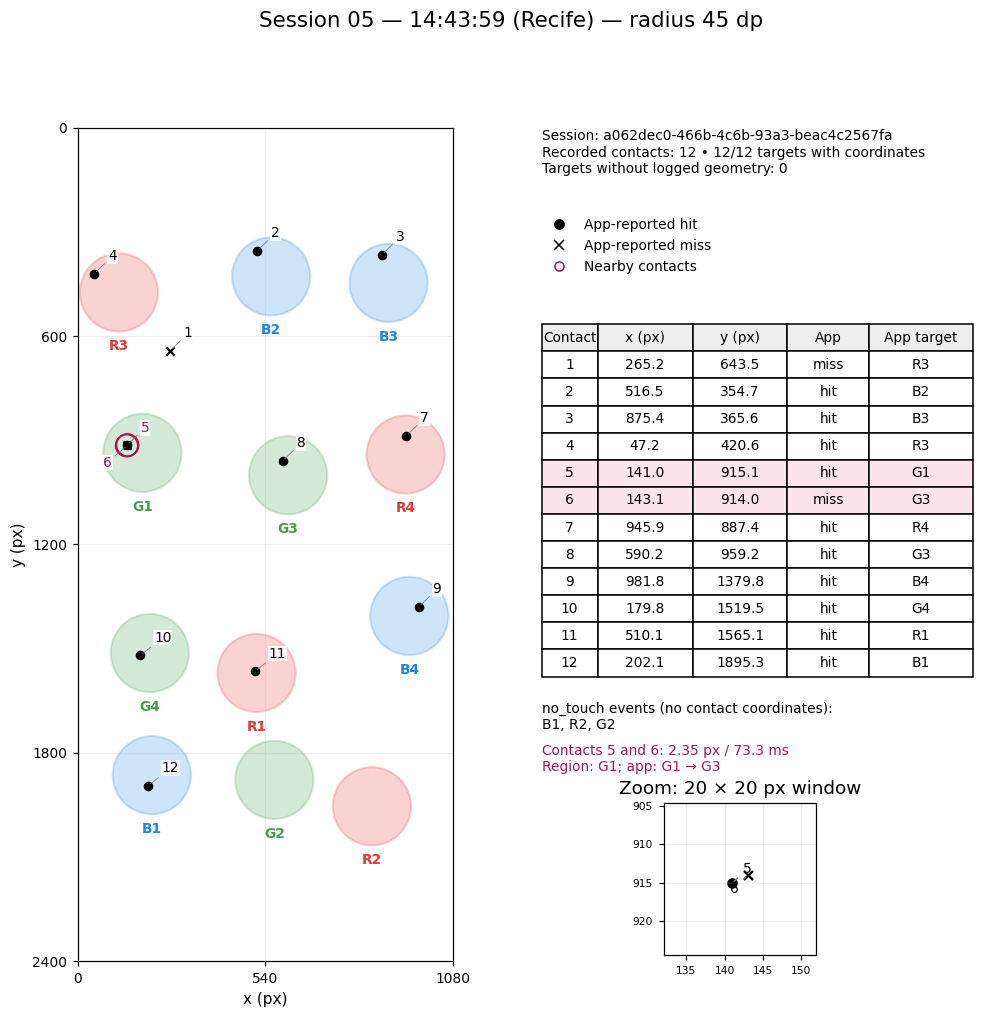

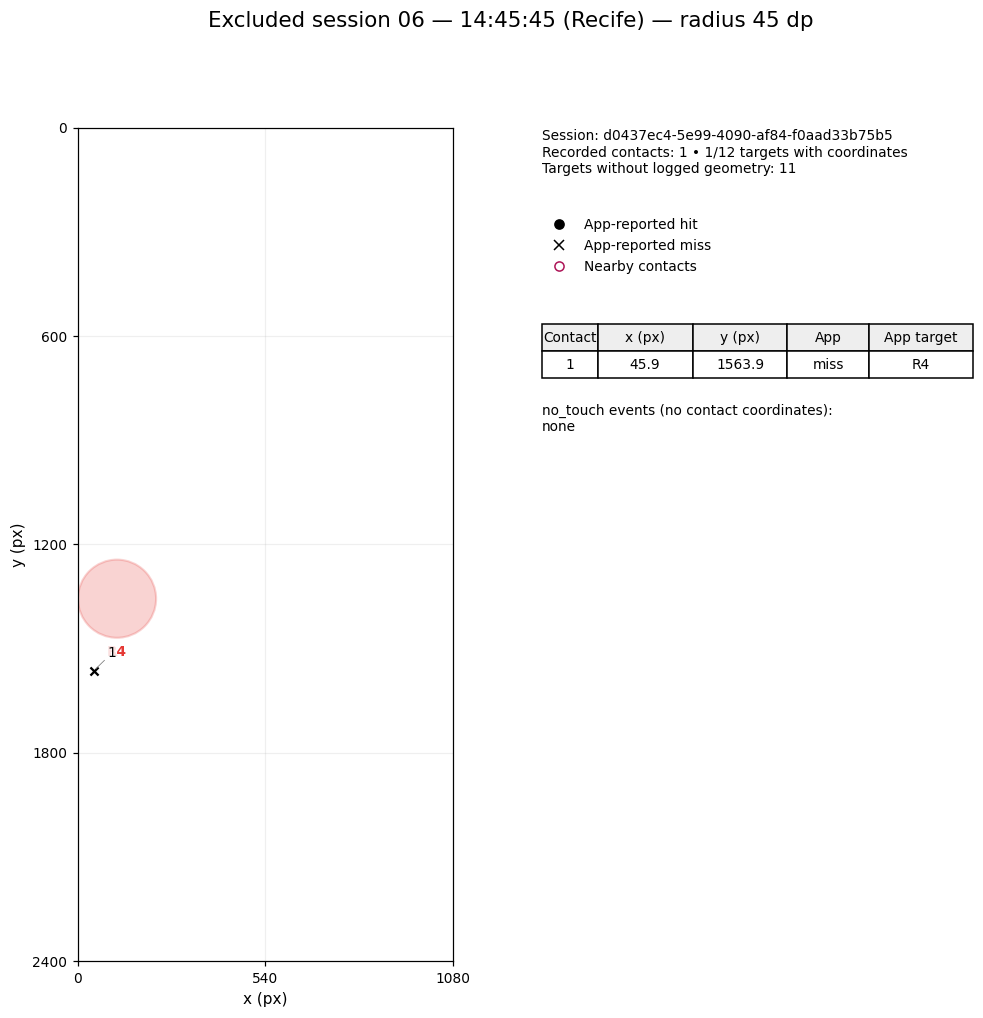

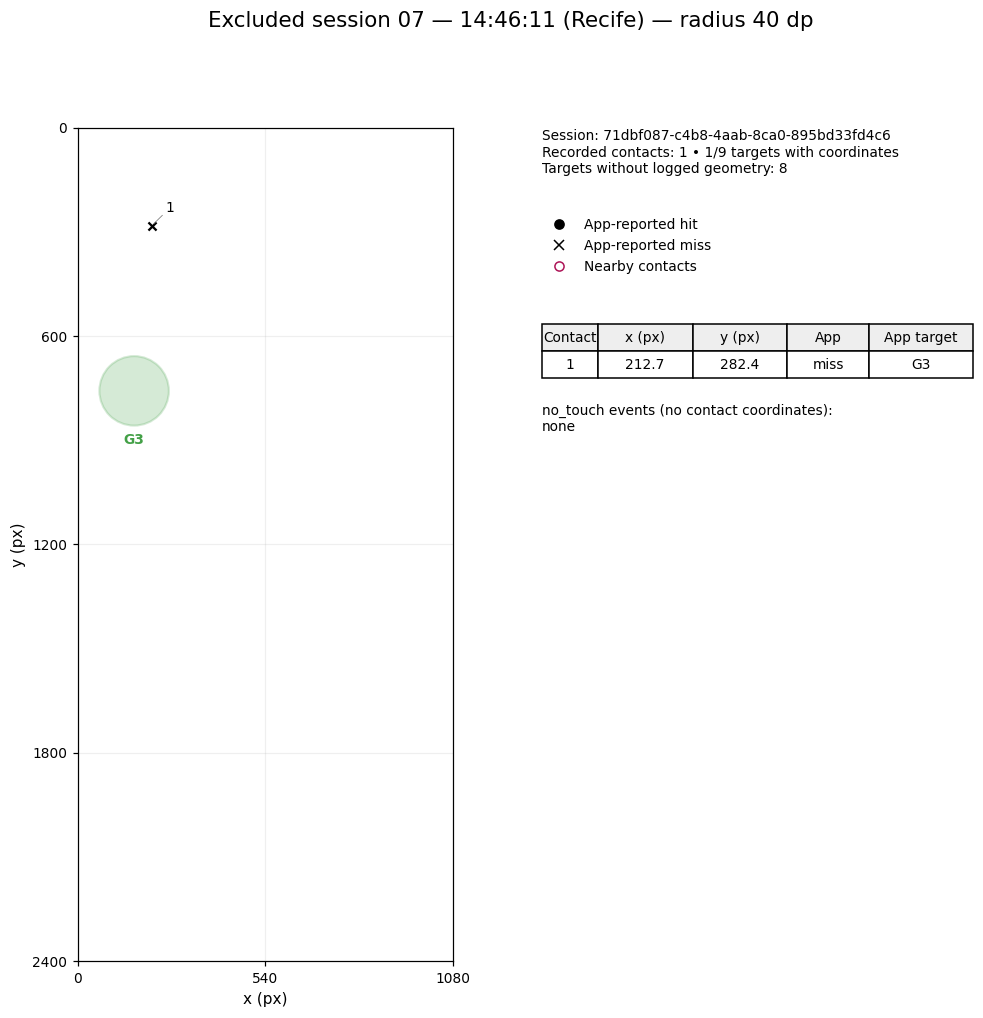

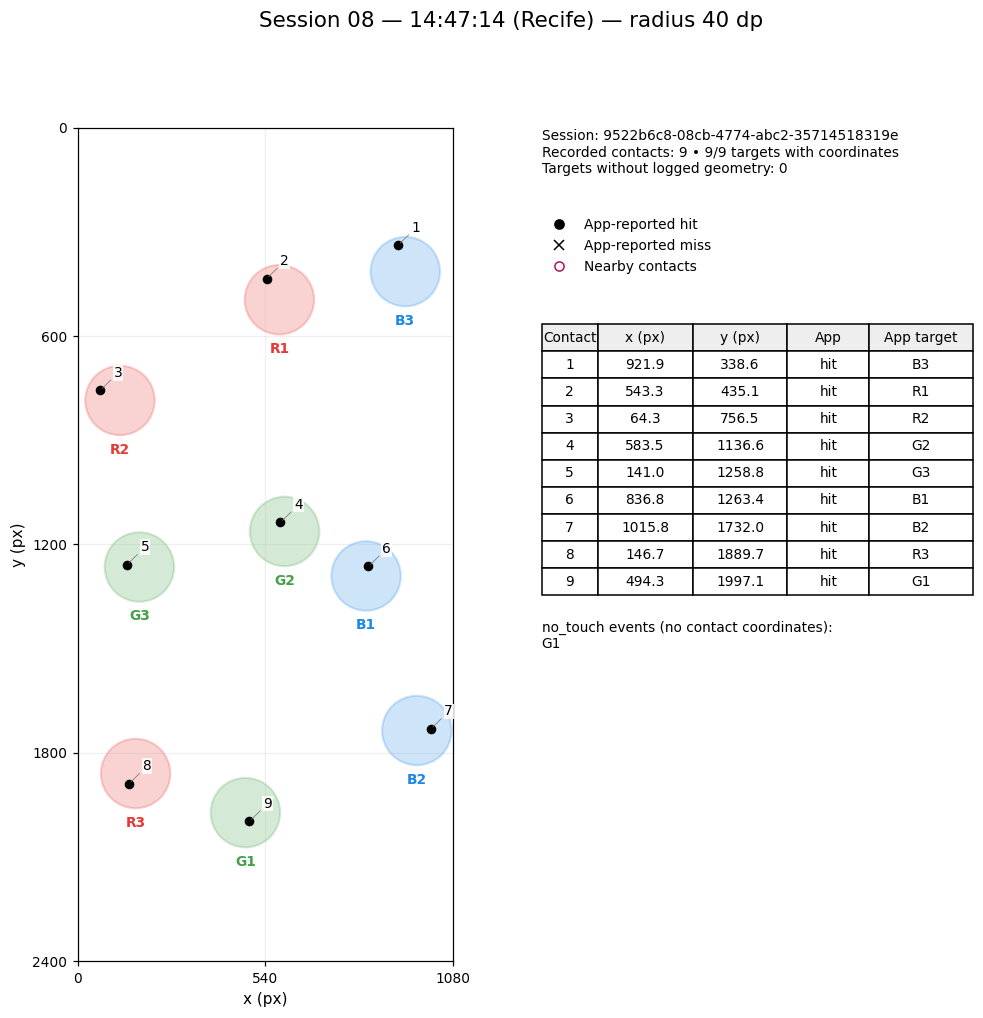

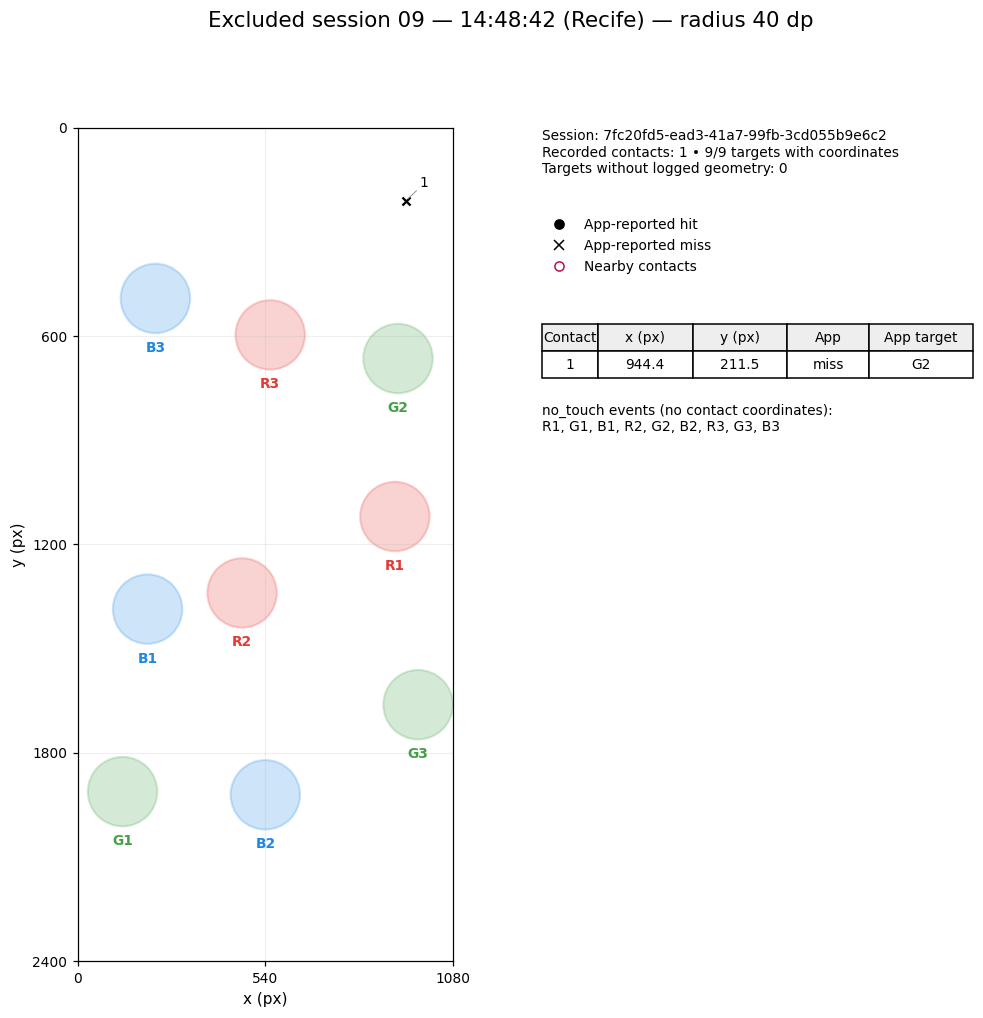

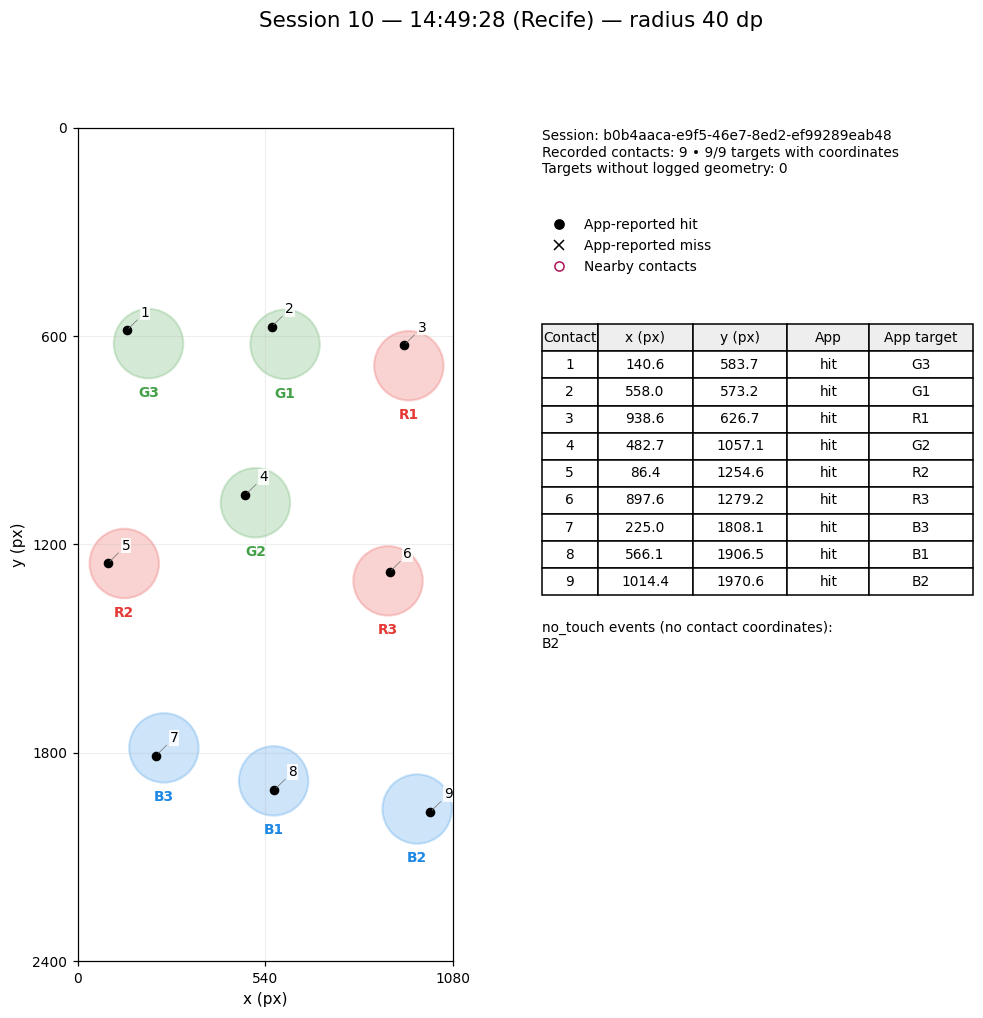

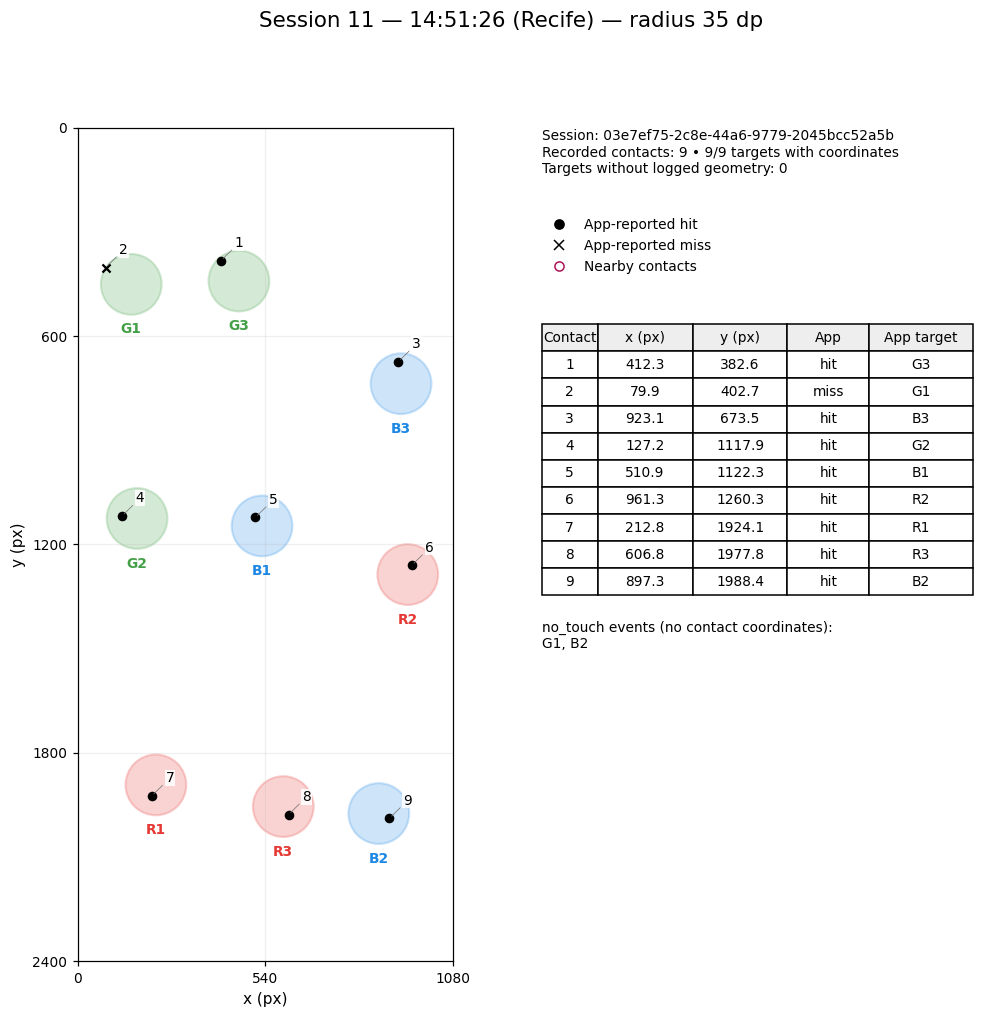

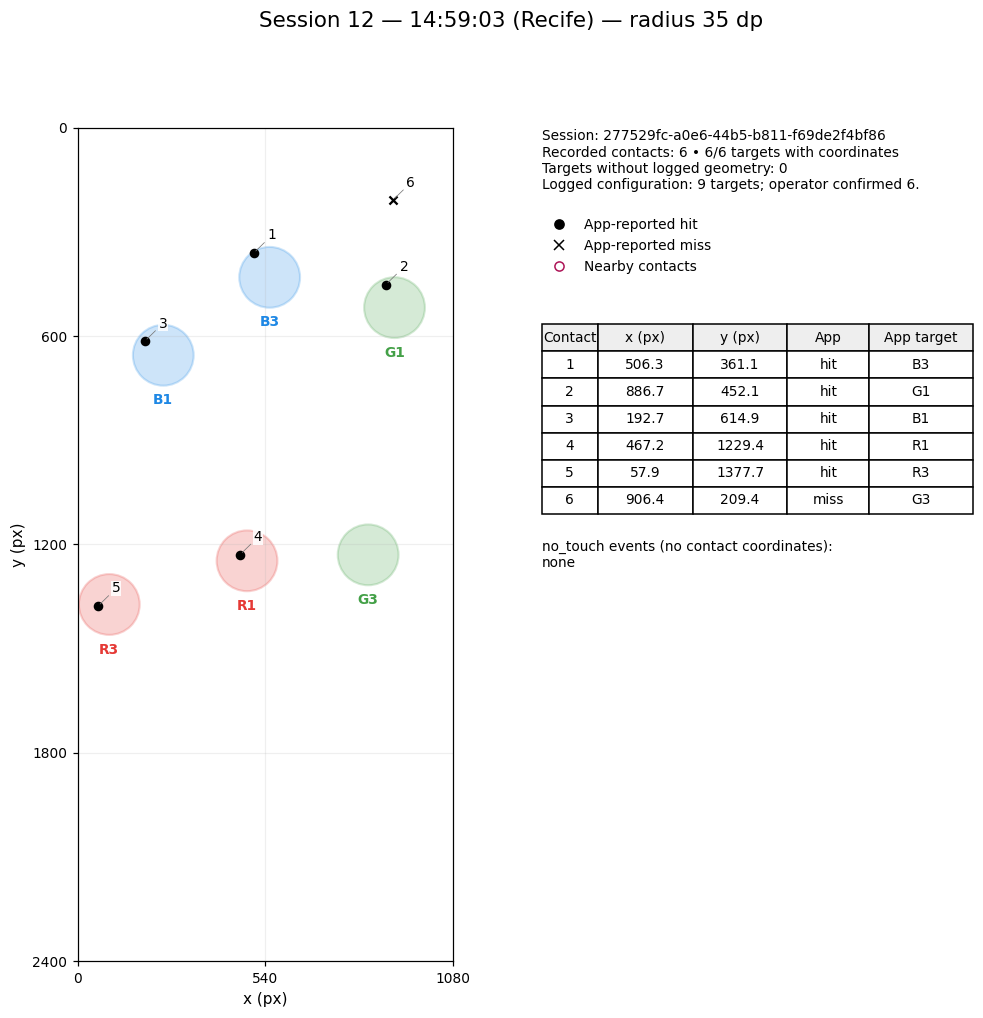

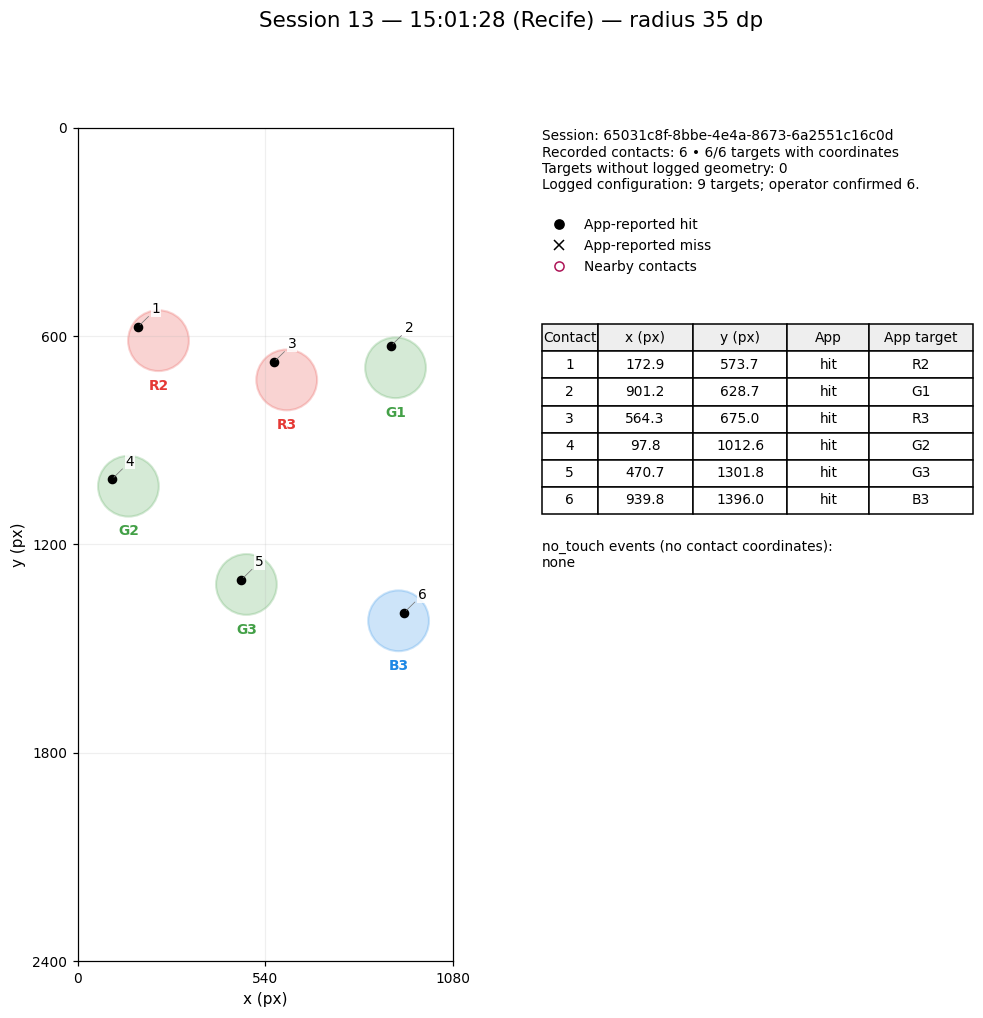

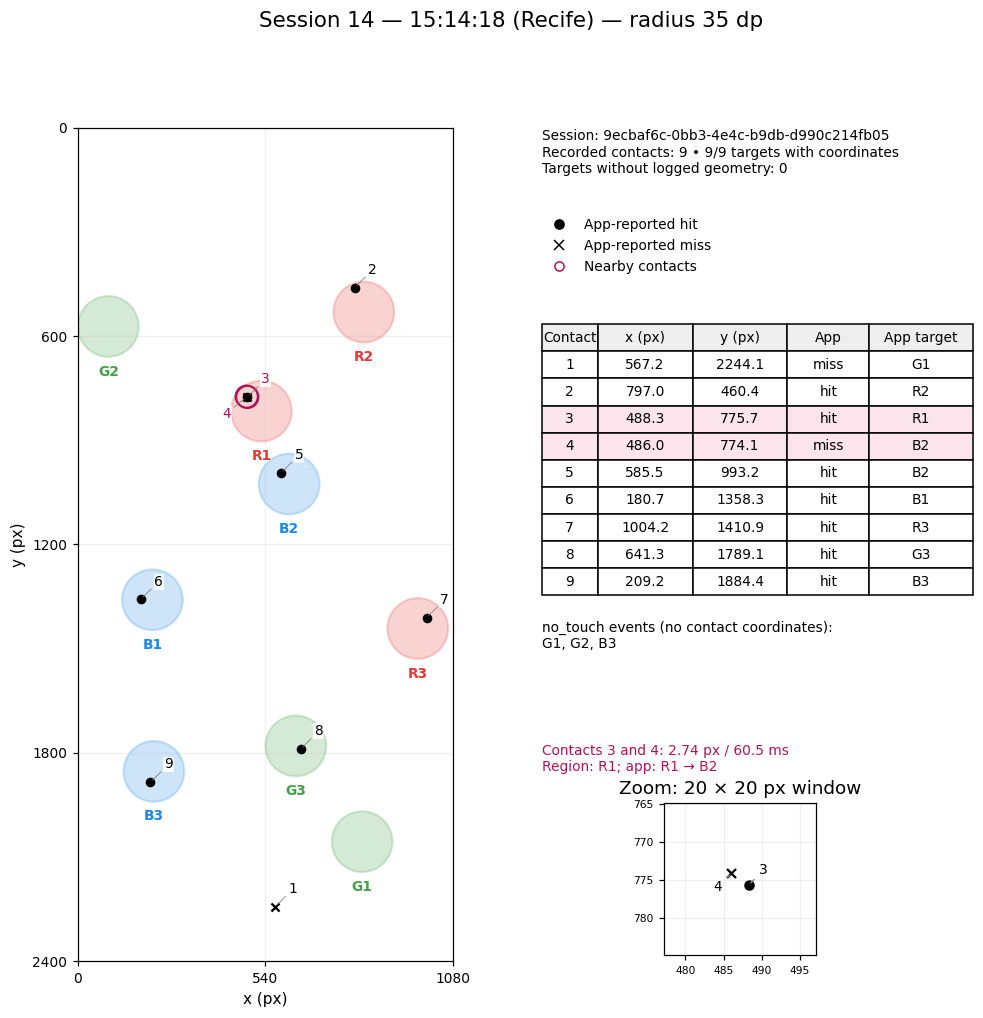

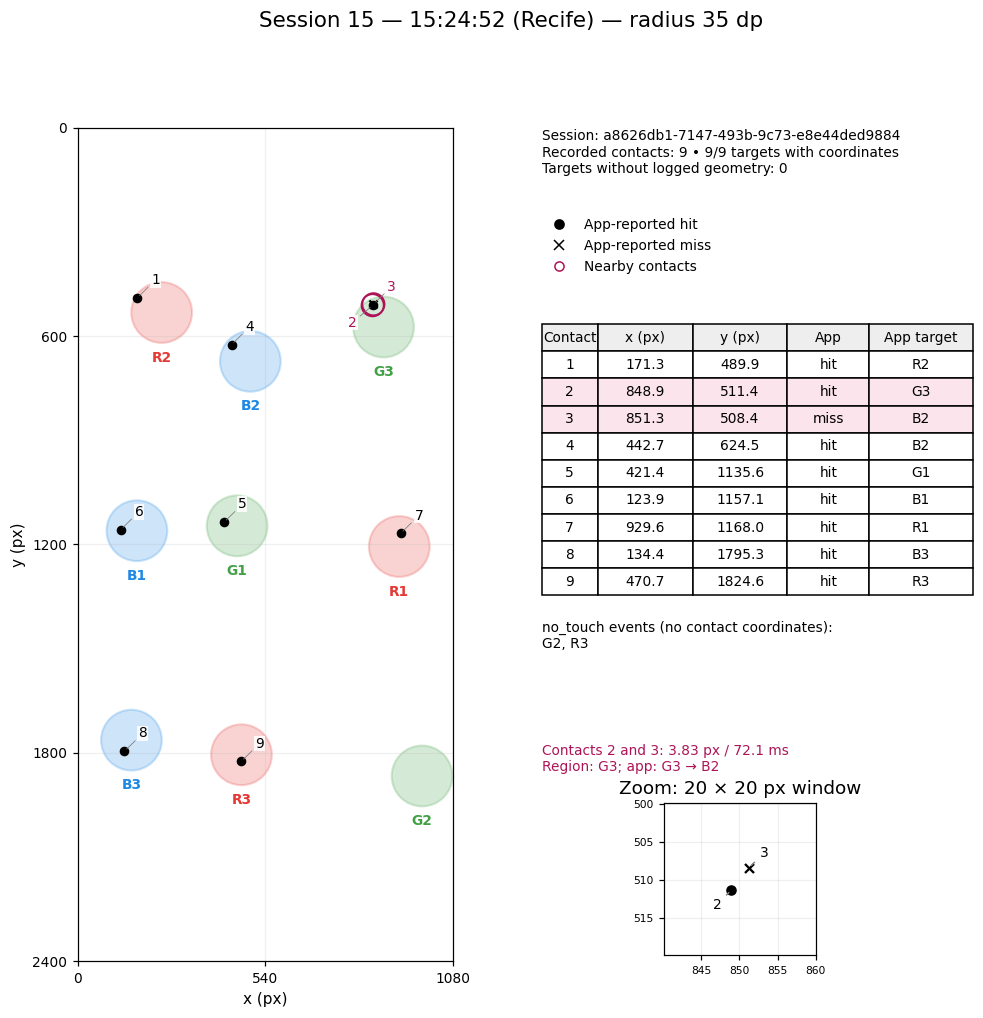

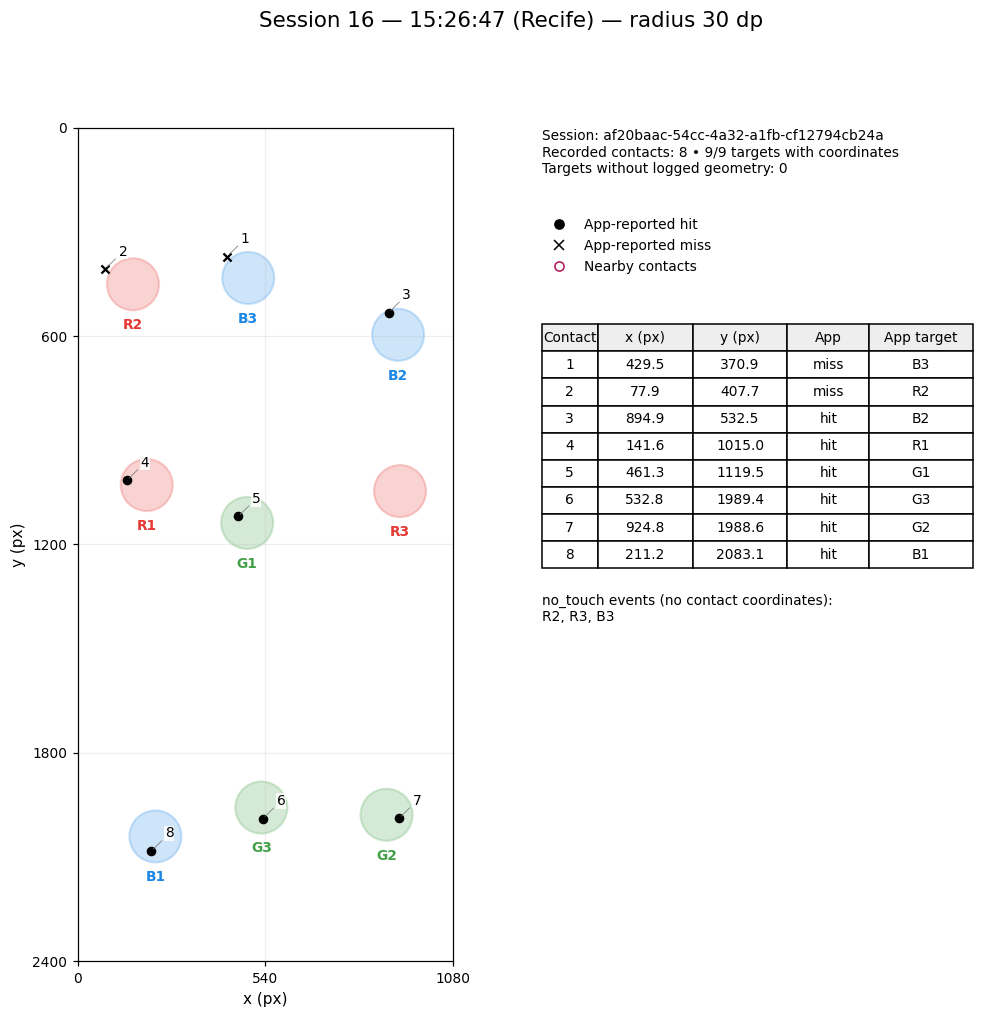

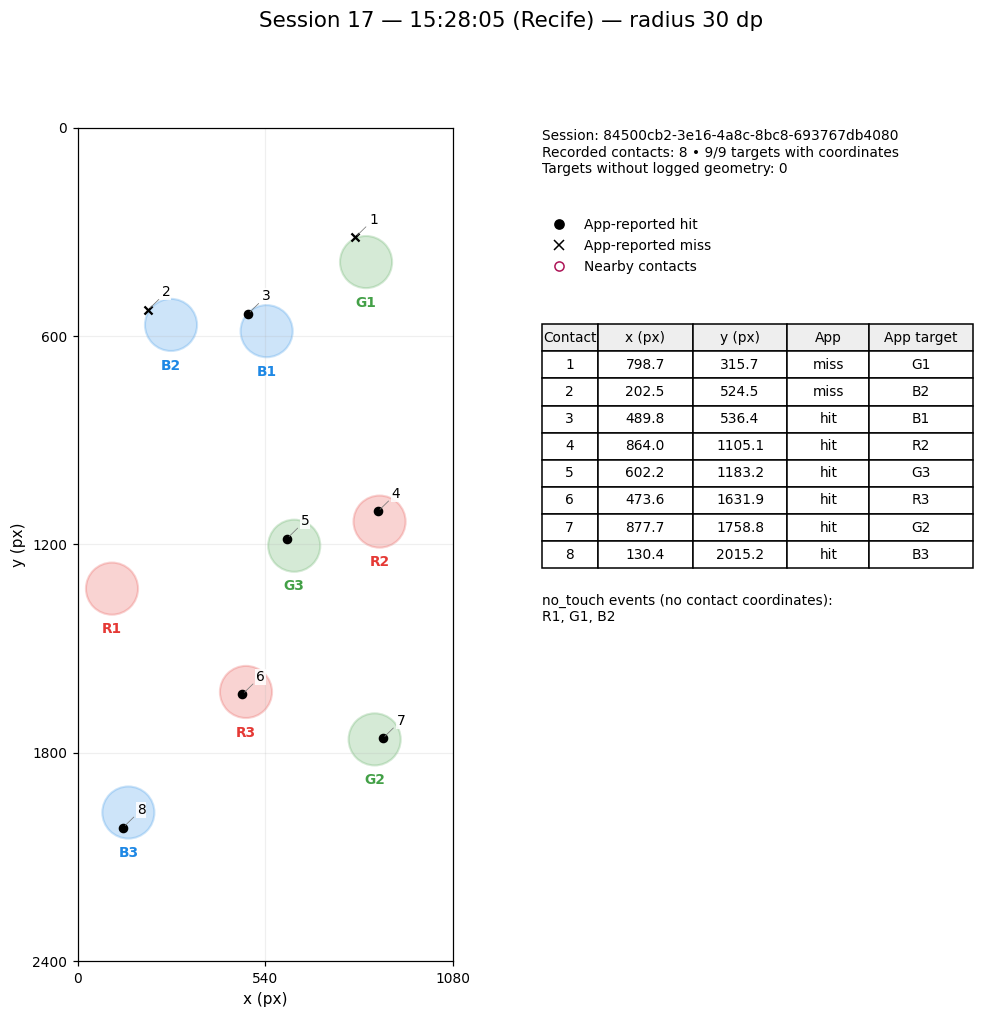

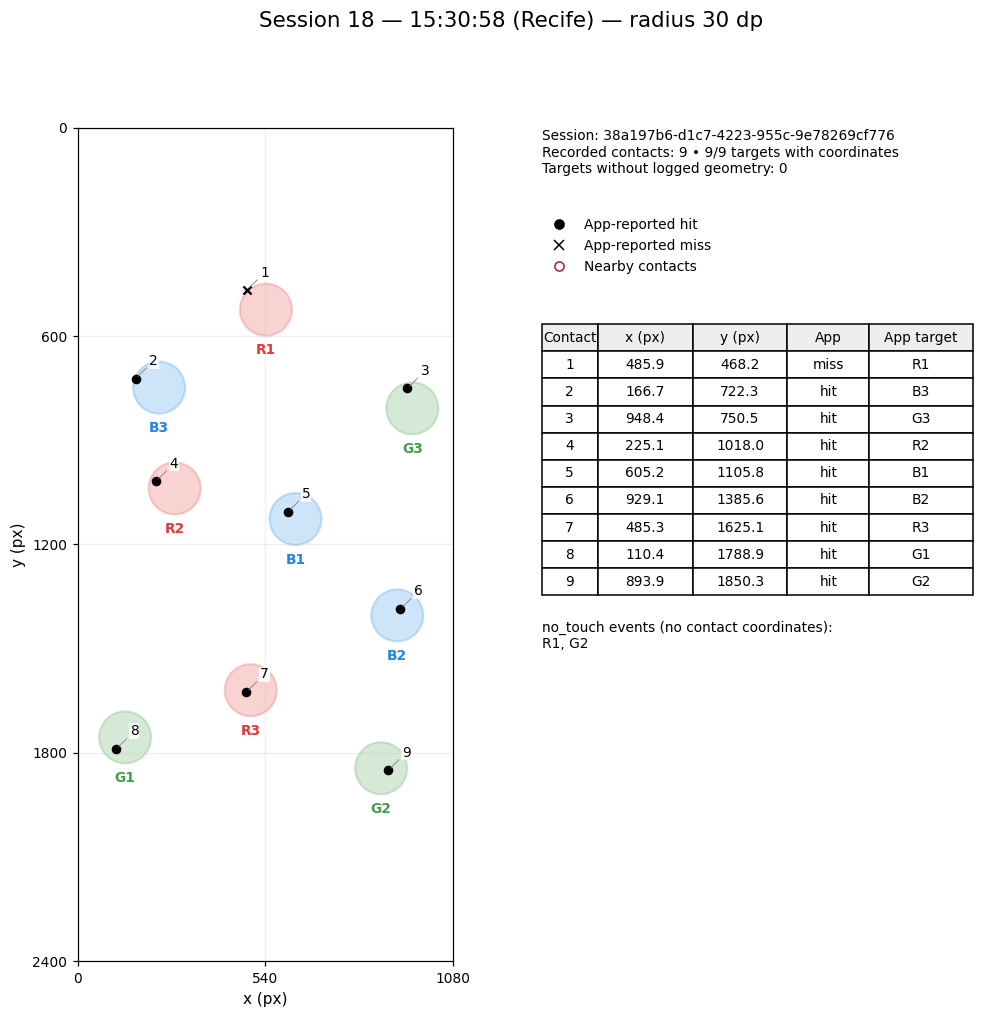

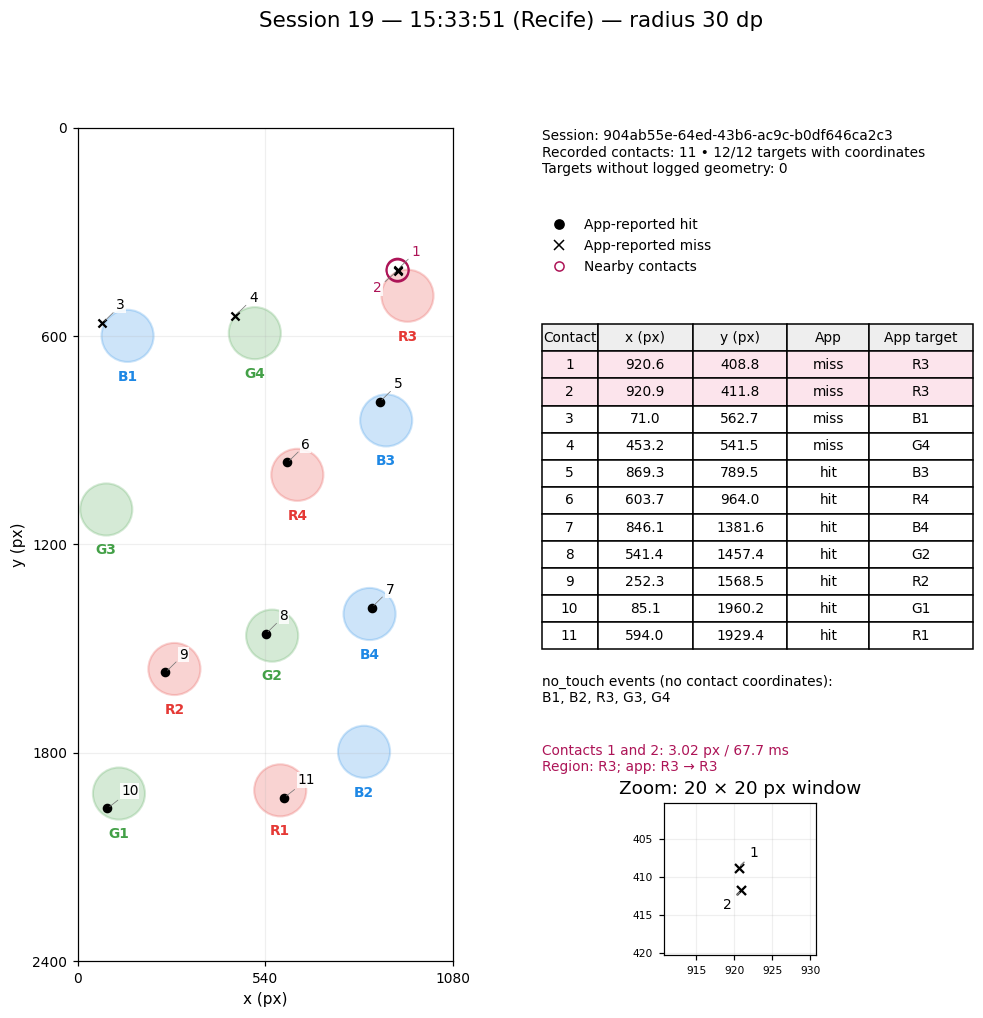

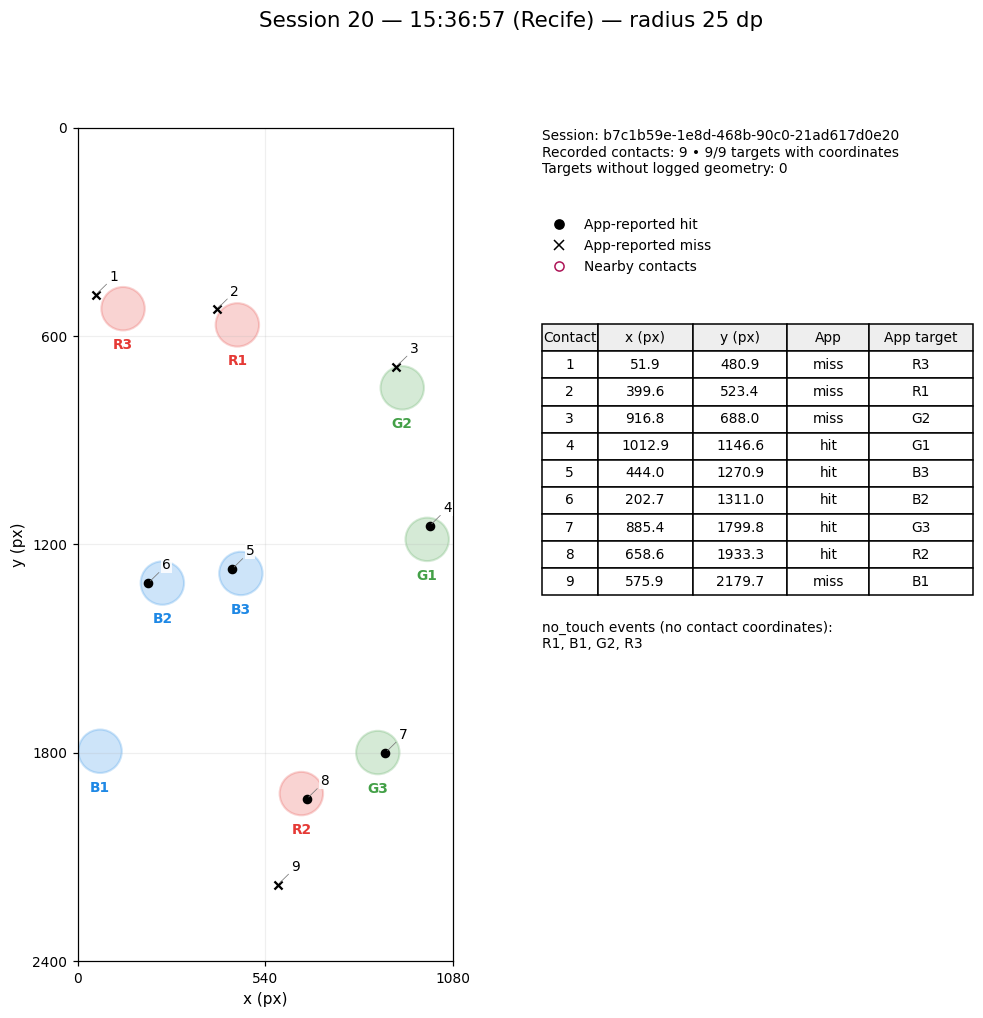

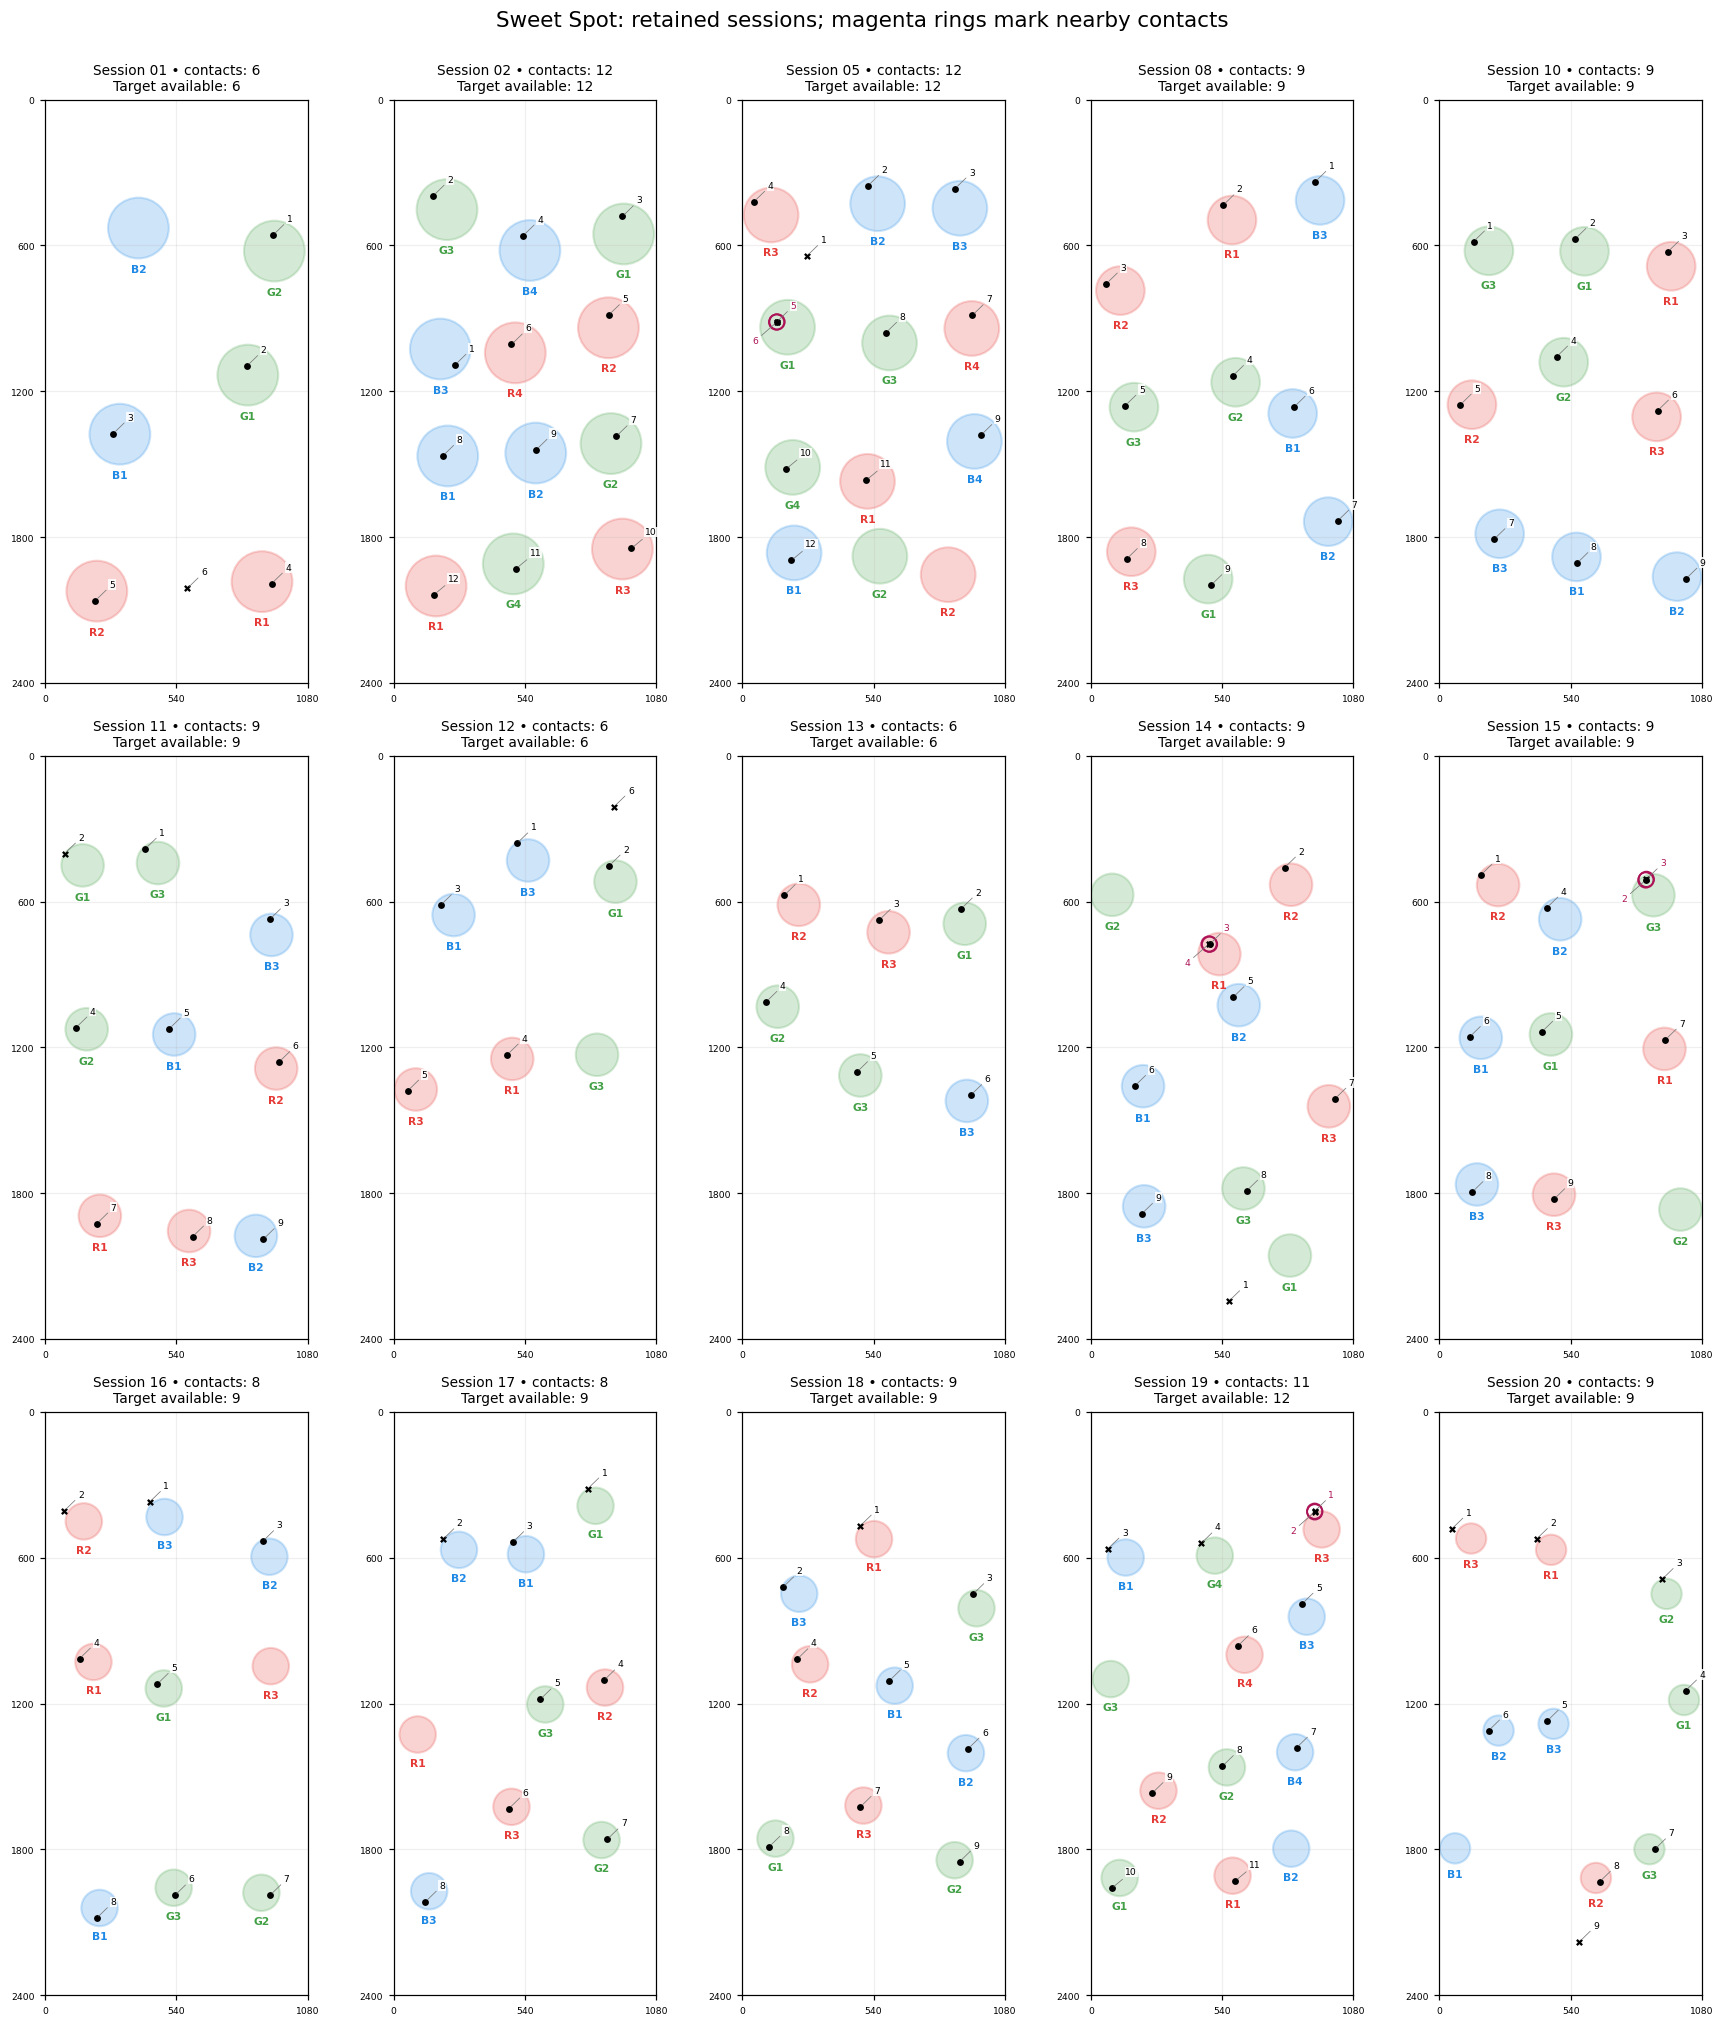

15 PNG maps and PDF with 15 pages exported.


In [5]:
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from matplotlib.backends.backend_pdf import PdfPages

MAPS = OUTPUT / 'maps'
MAPS.mkdir(exist_ok=True)
(OUTPUT / 'maps/excluded').mkdir(exist_ok=True)
TARGET_COLORS = {'red': '#e53935', 'green': '#43a047', 'blue': '#1e88e5'}

def short_target_name(tid):
    _, trio, color = tid.split('-')
    return {'red': 'R', 'green': 'G', 'blue': 'B'}[color] + str(int(trio))

def draw_screen(ax, rs, pairs, compact=False):
    ts = [r for r in rs if r['actual_touch_x'] is not None]
    geo = {r['target_id']: r for r in rs}
    marked_indices = {p[k] for p in pairs for k in ('touch_a', 'touch_b')}
    for tid, r in geo.items():
        color = TARGET_COLORS[tid.rsplit('-', 1)[-1]]
        ax.add_patch(Circle((r['target_center_x'], r['target_center_y']), r['target_radius'],
                            facecolor=color, edgecolor=color, alpha=.22, linewidth=1.4))
        ax.text(r['target_center_x'], r['target_center_y'] + r['target_radius'] + 22,
                short_target_name(tid), ha='center', va='top', color=color, fontsize=7 if compact else 9, weight='bold')
    for j, r in enumerate(ts, 1):
        x, y = r['actual_touch_x'], r['actual_touch_y']
        ax.scatter(x, y, marker='o' if r['result'] == 'hit' else 'x', color='black', s=12 if compact else 28, zorder=4)
        if j in marked_indices:
            ax.scatter(x, y, s=100 if compact else 210, facecolors='none', edgecolors='#ad1457', linewidths=1.2, zorder=5)
        offset = (9, 9) if j not in marked_indices or j % 2 else (-16, -14)
        ax.annotate(str(j), (x, y), xytext=offset, textcoords='offset points',
                    fontsize=6 if compact else 9, color='#ad1457' if j in marked_indices else 'black',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=.5),
                    arrowprops=dict(arrowstyle='-', color='#777777', linewidth=.5), zorder=6)
    ax.set(xlim=(0, rs[0]['screen_width']), ylim=(rs[0]['screen_height'], 0), aspect='equal')
    ax.set_xticks([0, 540, 1080])
    ax.set_yticks([0, 600, 1200, 1800, 2400])
    ax.tick_params(labelsize=6 if compact else 9)
    if not compact:
        ax.set(xlabel='x (px)', ylabel='y (px)')
    return ts, geo

legend = [Line2D([0], [0], marker='o', color='black', linestyle='none', label='App-reported hit'),
           Line2D([0], [0], marker='x', color='black', linestyle='none', label='App-reported miss'),
           Line2D([0], [0], marker='o', markerfacecolor='none', markeredgecolor='#ad1457', linestyle='none', label='Nearby contacts')]

with PdfPages(OUTPUT / 'maps/all_sessions.pdf') as pdf:
    for sid in original_order:
        rs = original_groups[sid]
        number = session_number[sid]
        pairs = [p for p in touch_pairs if p['session_number'] == number and p['nearby']]
        fig = plt.figure(figsize=(10.5, 10))
        gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=.22)
        ax = fig.add_subplot(gs[0, 0])
        info = fig.add_subplot(gs[0, 1])
        info.axis('off')
        ts, geo = draw_screen(ax, rs, pairs)
        config = rs[0]['configuration']
        time_label = rs[0]['timestamp'].astimezone(LOCAL_TIMEZONE).strftime('%H:%M:%S')
        label = "Excluded session" if number in EXCLUDED_SESSION_NUMBERS else "Session"
        fig.suptitle(f"{label} {number:02d} — {time_label} (Recife) — radius {rs[0]['target_radius_dp']:g} dp", fontsize=14)
        n = len(expected_target_ids(sid))
        missing_count = n - len(geo)
        config_note = f"\nLogged configuration: {config['target_count']} targets; operator confirmed {n}." if number in OPERATOR_TARGET_COUNTS else ''
        info.text(0, .99, f"Session: {sid}\nRecorded contacts: {len(ts)} • {len(geo)}/{n} targets with coordinates\nTargets without logged geometry: {missing_count}{config_note}",
                  transform=info.transAxes, va='top', fontsize=9)
        info.legend(handles=legend, loc='upper left', bbox_to_anchor=(-.02, .9), frameon=False, fontsize=9)
        table_data = [[j, f"{r['actual_touch_x']:.1f}", f"{r['actual_touch_y']:.1f}", r['result'], short_target_name(r['target_id'])] for j, r in enumerate(ts, 1)]
        height = .032 * (len(table_data) + 1)
        tbl = info.table(cellText=table_data, colLabels=['Contact', 'x (px)', 'y (px)', 'App', 'App target'],
                         colWidths=[.13, .22, .22, .19, .24], bbox=[0, .76 - height, 1, height], cellLoc='center')
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        for key, cell in tbl.get_celld().items():
            if key[0] == 0:
                cell.set_facecolor('#eeeeee')
            if key[0] in {p[k] for p in pairs for k in ('touch_a', 'touch_b')}:
                cell.set_facecolor('#fce4ec')
        manual = [short_target_name(r['target_id']) for r in rs if r['result'] == 'no_touch']
        info.text(0, .73 - height, 'no_touch events (no contact coordinates):\n' + (', '.join(manual) if manual else 'none'),
                  transform=info.transAxes, va='top', fontsize=9, wrap=True)
        for k, pair in enumerate(pairs):
            info.text(0, .265 - k * .30, f"Contacts {pair['touch_a']} and {pair['touch_b']}: {pair['distance_px']:.2f} px / {pair['interval_ms']:.1f} ms\n"
                      f"Region: {short_target_name(pair['shared_nearest_target_id']) if pair['shared_nearest_target_id'] else 'no shared nearby target'}; app: {short_target_name(pair['assigned_target_a'])} → {short_target_name(pair['assigned_target_b'])}",
                      transform=info.transAxes, va='top', fontsize=9, color='#ad1457')
            zoom = info.inset_axes([.12, .015 - k * .30, .68, .18])
            mid_x = (pair['x_a'] + pair['x_b']) / 2
            mid_y = (pair['y_a'] + pair['y_b']) / 2
            for j in (pair['touch_a'], pair['touch_b']):
                r = ts[j - 1]
                zoom.scatter(r['actual_touch_x'], r['actual_touch_y'], marker='o' if r['result'] == 'hit' else 'x', color='black', s=35)
                zoom.annotate(str(j), (r['actual_touch_x'], r['actual_touch_y']), xytext=(7, 7) if j % 2 else (-12, -12), textcoords='offset points', fontsize=9, arrowprops=dict(arrowstyle='-', color='gray'))
            zoom.set(xlim=(mid_x - 10, mid_x + 10), ylim=(mid_y + 10, mid_y - 10), aspect='equal', title='Zoom: 20 × 20 px window')
            zoom.tick_params(labelsize=7)
        if number not in EXCLUDED_SESSION_NUMBERS:
            pdf.savefig(fig, bbox_inches='tight')
        folder = 'maps/excluded' if number in EXCLUDED_SESSION_NUMBERS else 'maps'
        save_figure(f'{folder}/session_{number:02d}.png', fig)

panel_rows = math.ceil(len(session_order) / 5)
fig, axs = plt.subplots(panel_rows, 5, figsize=(16, 6.25 * panel_rows), squeeze=False)
for ax, sid in zip(axs.flat, session_order):
    number = session_number[sid]
    rs = groups[sid]
    pairs = [p for p in touch_pairs if p['session_number'] == number and p['nearby']]
    ts, geo = draw_screen(ax, rs, pairs, compact=True)
    ax.set_title(f"Session {number:02d} • contacts: {len(ts)}\nTarget available: {len(geo)}", fontsize=9)
for ax in axs.flat[len(session_order):]:
    ax.set_visible(False)
fig.suptitle('Sweet Spot: retained sessions; magenta rings mark nearby contacts', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .98))
save_figure('maps/session_overview.png', fig)
assert len(list(MAPS.glob('session_[0-9][0-9].png'))) == len(sessions)
print(f"{len(sessions)} PNG maps and PDF with {len(sessions)} pages exported.")

## 4. Summary and checks

Source records, operator annotations, and derived fractions remain separate.
The analysis is descriptive: target size and session time varied together, and contacts are clustered within sessions.
No claim is made about independent robot actions, unlogged contacts, software-change timing, or the cause of repeated contacts.
IMU fields remain in the raw data but are not processed in this notebook.

In [6]:
def check_pair_detection():
    base = dict(groups[session_order[0]][0])
    a = dict(base, target_id='trio-001-red', target_center_x=100, target_center_y=100,
             actual_touch_x=100, actual_touch_y=100, result='hit')
    b = dict(base, target_id='trio-001-blue', target_center_x=500, target_center_y=500,
             actual_touch_x=103, actual_touch_y=100, result='miss',
             timestamp=a['timestamp'] + timedelta(milliseconds=70))
    manual = dict(a, actual_touch_x=None, actual_touch_y=None, result='no_touch')
    c = dict(b, actual_touch_x=500, actual_touch_y=500,
             timestamp=a['timestamp'] + timedelta(seconds=2))
    pp = detect_pairs([a, manual, b, c])
    assert len(pp) == 3  # Three pairs from three contacts; manual events excluded.
    assert pp[0]['distance_px'] == 3 and math.isclose(pp[0]['interval_ms'], 70)
    assert pp[0]['rapid_repeated_contact_candidate'] == (3 <= NEARBY_DISTANCE_DP * base['target_radius'] / base['target_radius_dp'] and 70 <= RAPID_CONTACT_WINDOW_MS)
    assert pp[0]['same_target_region']
    assert pp[0]['assigned_target_a'] != pp[0]['assigned_target_b']
    assert all(p['nearby'] == (p['distance_px'] <= NEARBY_DISTANCE_DP * base['target_radius'] / base['target_radius_dp']) for p in pp)
    assert len(touch_pairs) == sum(math.comb(s['touches'], 2) for s in sessions)
    print('Spatial check passed; different target IDs do not hide repeated coordinates.')
check_pair_detection()


import platform
import importlib.metadata

assert len(records) + len(excluded_line_numbers) == len(original_records)
assert len(targets) == effective_targets
assert all(s['recorded_target_count'] + s['targets_without_records'] == s['effective_target_count'] for s in sessions)
assert all(s['effective_target_count'] == 6 and s['logged_target_count'] == 9 and s['completion_basis'] == 'operator_confirmed'
           for s in sessions if s['session_number'] in OPERATOR_TARGET_COUNTS)
manifest = dict(source_file=str(SOURCE.relative_to(ROOT)), source_sha256=hashlib.sha256(raw).hexdigest(),
    retained_sessions=len(sessions), retained_events=len(records), retained_contacts=total_contacts,
    excluded_session_numbers=sorted(EXCLUDED_SESSION_NUMBERS), operator_target_counts=OPERATOR_TARGET_COUNTS,
    effective_targets=effective_targets, logged_configuration_targets=logged_targets,
    nearby_distance_dp=NEARBY_DISTANCE_DP, rapid_contact_window_ms=RAPID_CONTACT_WINDOW_MS,
    target_region_margin_dp=TARGET_MARGIN_DP, python_version=platform.python_version(),
    packages={name: importlib.metadata.version(name) for name in ['numpy', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel', 'matplotlib-inline']})
(OUTPUT / 'manifest.json').write_text(json.dumps(manifest, indent=2) + '\n', encoding='utf-8')
report = f"""# Sweet Spot: simple descriptive analysis

## Selection and provenance

Source: `{manifest['source_file']}`. SHA-256: `{manifest['source_sha256']}`.
The original file has {len(original_records)} events in {len(original_groups)} sessions.
Sessions 3, 4, 6, 7, and 9 were excluded retrospectively by the operator as interrupted trials.
The retained population has **{len(sessions)} sessions, {len(records)} events, and {total_contacts} recorded contacts**.
Source measurements and original session/target identifiers are preserved.

Sessions 12 and 13 are completed six-target trials according to the operator (two reported trios).
Their JSON configuration states nine targets. The correction is an external annotation, not a rewrite of the raw logs.
The six logged IDs, including an uneven RGB identifier distribution in session 13, do not independently verify two complete RGB trios. The metadata discrepancy remains unresolved.

## Observed outcomes

- App-reported hits: **{total_hits}**; misses: **{total_contacts - total_hits}**.
- Recorded-contact hit fraction: **{total_hits}/{total_contacts} = {total_hits / total_contacts:.2%}**.
- Target hit coverage with operator-corrected counts: **{hit_targets}/{effective_targets} = {hit_targets / effective_targets:.2%}**.
- Raw-configuration sensitivity: **{hit_targets}/{logged_targets} = {hit_targets / logged_targets:.2%}**.

All registered contacts, including repeats, remain in the contact fraction. Targets with any hit are counted once in the target fraction.
Neither fraction estimates independent robot-action accuracy or unlogged outcomes.

## Repeated contacts

| Session | Contact indices | Separation (px) | Interval (ms) | App assignments |
|---|---|---:|---:|---|
"""
for pair in nearby_pairs:
    report += f"| {pair['session_number']} | {pair['touch_a']} and {pair['touch_b']} | {pair['distance_px']:.2f} | {pair['interval_ms']:.1f} | {pair['assigned_target_a']} → {pair['assigned_target_b']} |\n"
report += f"""
There are {len(nearby_pairs)} nearby pairs; {len(rapid_pairs)} meet the exploratory rapid-repeat criterion.
The default thresholds are {NEARBY_DISTANCE_DP} dp and {RAPID_CONTACT_WINDOW_MS} ms. A close, rapid pair is consistent with repeated contact, without proving its physical cause.
App outcomes are preserved even when an assigned target differs from the nearby circle.

## Scope

This analysis covers recorded outcomes, contact repetition, and maps. IMU, application timing, calibration, and software-history analyses are not performed.
Target size and session conditions vary together; contacts are clustered within sessions. No causal or independent-trial inference is made.
The after-update raw exports are preserved but are not part of this Sweet Spot analysis.
See data/annotations/ for operator decisions and archive/detailed_analysis/ for the previous detailed snapshot.
"""
(OUTPUT / 'summary.md').write_text(report, encoding='utf-8')
print(report)
print('Processing and spatial classification checks passed.')

Spatial check passed; different target IDs do not hide repeated coordinates.
# Sweet Spot: simple descriptive analysis

## Selection and provenance

Source: `data/raw/sweetspot/touch_results_2026-10-06-sweetspot.jsonl`. SHA-256: `290accd48b1739358913f6846d241b868f7a73a8317a14dd1b178490747f67f5`.
The original file has 177 events in 20 sessions.
Sessions 3, 4, 6, 7, and 9 were excluded retrospectively by the operator as interrupted trials.
The retained population has **15 sessions, 163 events, and 132 recorded contacts**.
Source measurements and original session/target identifiers are preserved.

Sessions 12 and 13 are completed six-target trials according to the operator (two reported trios).
Their JSON configuration states nine targets. The correction is an external annotation, not a rewrite of the raw logs.
The six logged IDs, including an uneven RGB identifier distribution in session 13, do not independently verify two complete RGB trios. The metadata discrepancy remains unresolved.
